In [2]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2




r_seed = 42

WORKDIR = 'C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git/'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/2024-03-15_21-38-39 - Copia"

In [3]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [4]:
## get dataset
pd.set_option("display.precision", 9)

# select only sensor data from smart watches
data = pd.read_csv('activity_recognition_data_watch_concat_by_comparacao_grupos.csv',dtype={"value": "float64"})

In [5]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [6]:
data.isnull().sum()

pessoa_x              0
atividade             0
tempo_acelerômetro    0
acelerômetro_x        0
acelerômetro_Y        0
acelerômetro_Z        0
tempo_gyro            0
giroscópio_x          0
giroscópio_Y          0
giroscópio_Z          0
dtype: int64

In [7]:
#remove the null class
data=data.dropna()

# **Data Exploration**

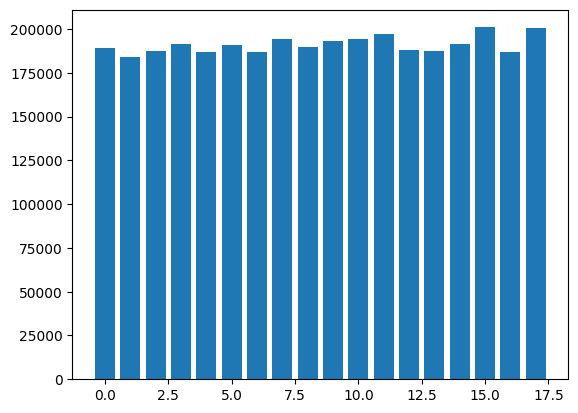

In [8]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

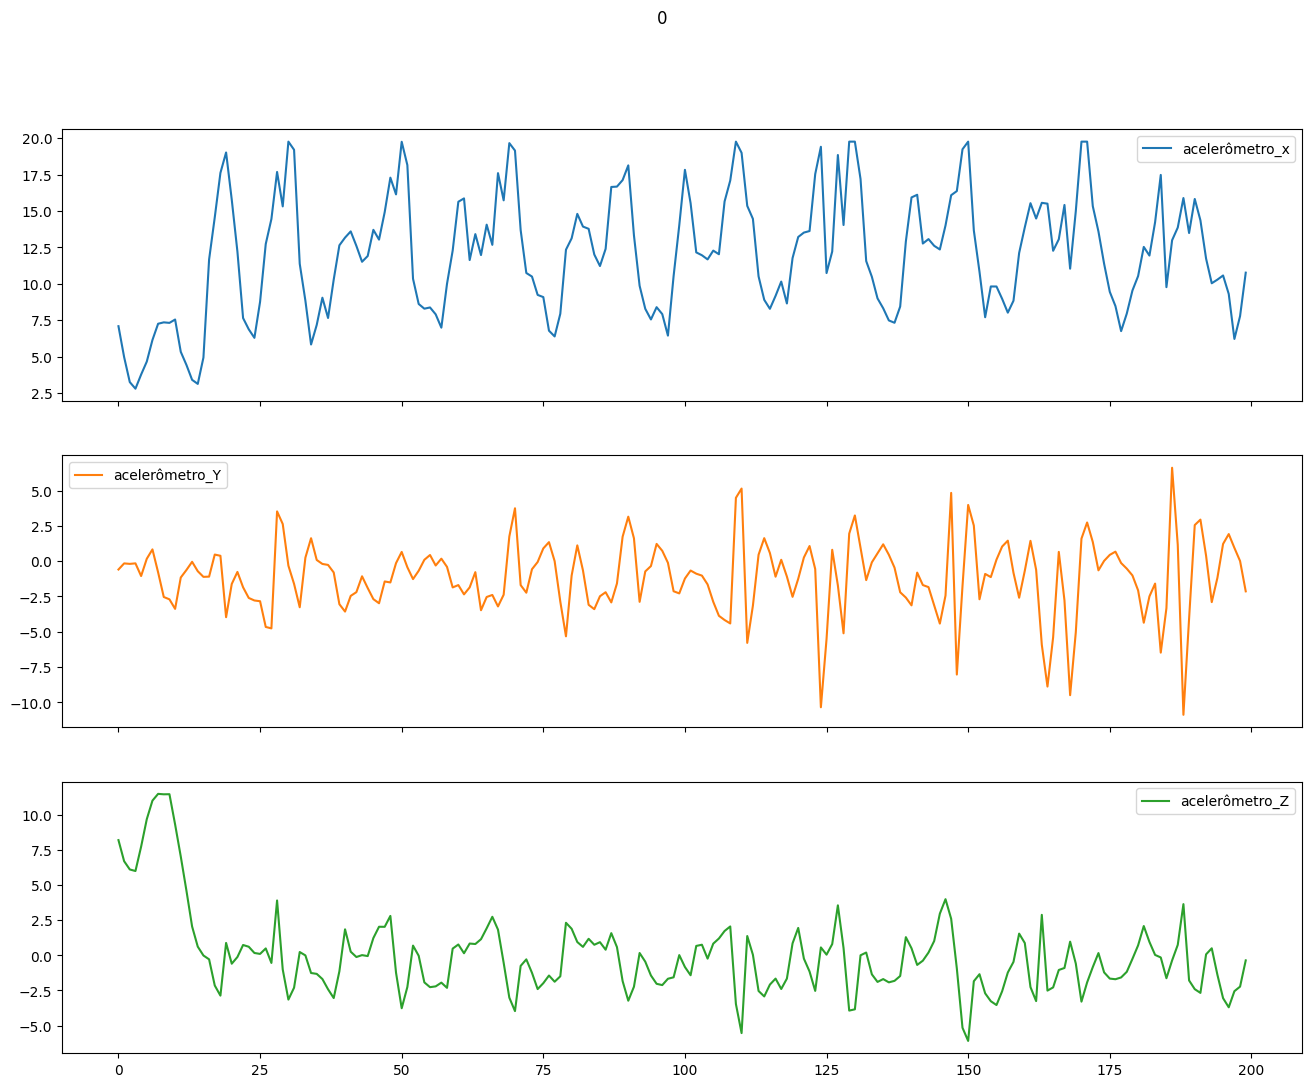

In [9]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

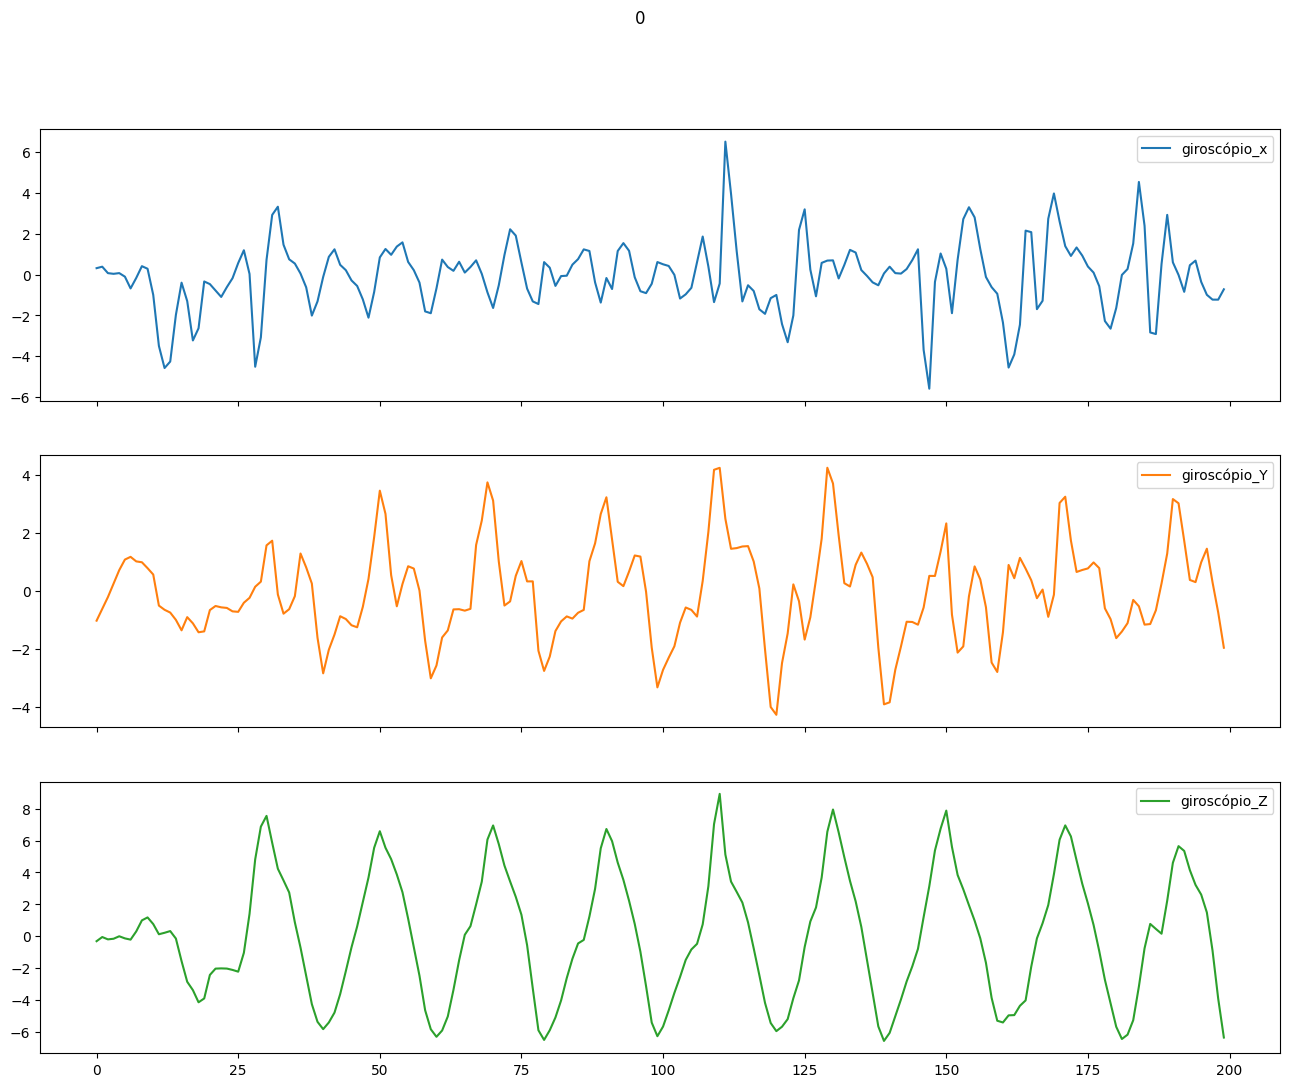

In [10]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

In [11]:
data = data[data.pessoa_x!=1629]

In [12]:
data.pessoa_x.unique()

array([1600, 1601, 1602, 1603, 1604, 1605, 1606, 1607, 1608, 1609, 1610,
       1611, 1612, 1613, 1614, 1615, 1616, 1617, 1618, 1619, 1620, 1621,
       1622, 1623, 1624, 1625, 1626, 1627, 1628, 1630, 1631, 1632, 1633,
       1634, 1635, 1636, 1637, 1638, 1639, 1640, 1641, 1642, 1643, 1644,
       1645, 1646, 1647, 1648, 1649, 1650], dtype=int64)

In [13]:
data = data.reset_index(drop=True)

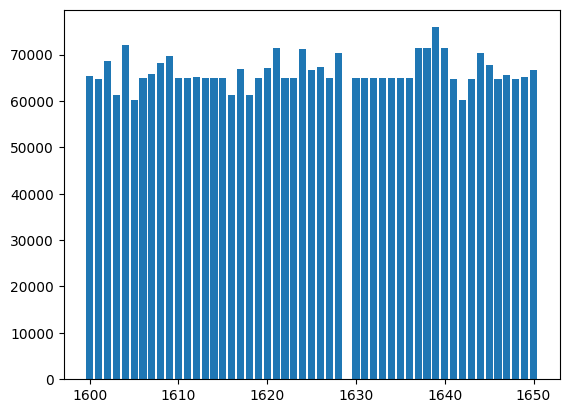

In [14]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [15]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,1,2,3,13,16])]

In [16]:
# Define the mapping dictionary
mapping_dict = {13:4,16:5}

In [17]:
data["atividade"] = data["atividade"].replace(to_replace=mapping_dict)

In [18]:
data.shape

(1083818, 10)

In [19]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [20]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [21]:
data.shape

(1083818, 10)

# **Models**

In [22]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [23]:
def apply_segmentation_no_sliding_window(df_data):
# Define window size and step size
    window_size = 200
    step_size = 20

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 200 segment has the value in label
        label_consistency = (df_data[['atividade']][start_idx:end_idx].nunique()==1) 
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [24]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [25]:
X_test_data = data[data.pessoa_x.isin(np.arange(1608,1614))]

In [26]:
print(X_test_data.shape)

(127367, 10)


In [27]:
X_test_data = X_test_data.reset_index(drop = True)

In [28]:
X_test_data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1608,0,789657572953540,9.0849480,-0.4616320,-0.81088620,789657622453540,1.97518240,0.12428254,3.19449260
1,1608,0,789657622453540,7.1815577,-0.7728782,-0.58343700,789657671953540,1.47237770,0.40444708,2.38169570
2,1608,0,789657671953540,5.5008283,1.9349640,-0.17642274,789657721453540,0.34532782,0.30005115,1.50604840
3,1608,0,789657721453540,5.1847935,2.4090160,-0.18121114,789657770953540,-1.17054340,-0.16973044,-0.20583145
4,1608,0,789657770953540,7.1911345,0.5415385,-0.20036475,789657820453540,-1.89918430,-0.52978980,-3.08311060


In [29]:
X_test_data.tail()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
127362,1613,5,613406335310890,19.6243740,-10.1770030,19.6405330,613406335310890,-0.48639628,-3.1697788,0.034995534
127363,1613,5,613406385275139,-4.6474447,-2.8938417,8.3686320,613406385275139,0.70883040,-0.3191311,-0.299497500
127364,1613,5,613406435239363,-1.9850925,-8.2664300,13.1570360,613406435239363,-0.56522584,0.6950006,-0.793780200
127365,1613,5,613406485203551,-6.8836293,-4.9025770,7.0350623,613406485203551,0.43186167,1.1370853,-0.286714320
127366,1613,5,613406535167693,-5.1550155,-3.5785832,4.2673655,613406535167693,0.34770578,1.6803702,0.150044100


In [30]:
X_test_data.pessoa_x.unique()

array([1608, 1609, 1610, 1611, 1612, 1613], dtype=int64)

In [31]:
print(f"percentage of validation is {X_test_data.shape[0]/data.shape[0]}")

percentage of validation is 0.11751696318016494


In [32]:
X_test_data['atividade'].value_counts()

atividade
1    21617
2    21617
3    21617
5    21616
0    21615
4    19285
Name: count, dtype: int64

In [33]:
grouped_data = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()
print(grouped_data)

atividade       0       1        2       3        4       5
pessoa_x                                                   
1600       3603.0  3604.0   3604.0  3604.0   3603.0  3604.0
1601       7202.0     NaN   3601.0  7202.0   3602.0  3601.0
1602       3603.0  3603.0   3603.0  3603.0   3603.0  3603.0
1603          NaN  3602.0   7204.0     NaN   3602.0  3602.0
1604       3603.0  3603.0   3604.0  3603.0   3603.0  3603.0
1605          NaN     NaN  10806.0     NaN      NaN     NaN
1606       3603.0  3603.0   3603.0  3603.0   3603.0  3603.0
1607       3603.0  3602.0   3602.0  3601.0  10806.0  3601.0
1608       3603.0  3603.0   3603.0  3603.0   3603.0  3603.0
1609       3603.0  3603.0   3603.0  3603.0   4873.0  3603.0
1610       3603.0  3603.0   3603.0  3603.0   3603.0  3603.0
1611       3603.0  3604.0   3603.0  3603.0   3603.0  3603.0
1612       3603.0  3603.0   3603.0  3603.0   3603.0  3603.0
1613       3600.0  3601.0   3602.0  3602.0      NaN  3601.0
1614       3601.0  3600.0   3616.0  3601

In [34]:
X_test_data = X_test_data[['pessoa_x','acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [34]:
segments_test,targets_test = apply_segmentation_no_sliding_window(X_test_data.loc[:, X_test_data.columns != 'pessoa_x'])
print(targets_test.shape)
print(segments_test.shape)

(636, 200, 1)
(636, 200, 6)


In [35]:
segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)
print(targets_test.shape)
print(segments_test.shape)

(602, 200, 1)
(602, 200, 6)


In [36]:
targets_test = targets_test.reshape(targets_test.shape[0],200)

In [37]:
print(targets_test.shape)

(602, 200)


In [38]:
print(targets_test)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [5 5 5 ... 5 5 5]
 [5 5 5 ... 5 5 5]
 [5 5 5 ... 5 5 5]]


In [39]:
labels_test = targets_test[:,0]

In [40]:
print(labels_test)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5
 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 4 4 4 4 4 4 4 4 4 4 

In [41]:
print(labels_test.shape)

(602,)


In [42]:
labels_test_categorical = to_categorical(labels_test,num_classes=6)

In [43]:
print(labels_test_categorical)

[[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]]


In [44]:
print(labels_test_categorical.shape)

(602, 6)


In [45]:
lstm_model = tf.keras.models.load_model(WORKDIR+'/Model/best_models_saved')

In [46]:
lstm_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 224)               206976    
                                                                 
 dense (Dense)               (None, 96)                21600     
                                                                 
 flatten (Flatten)           (None, 96)                0         
                                                                 
 dense_1 (Dense)             (None, 6)                 582       
                                                                 
Total params: 229158 (895.15 KB)
Trainable params: 229158 (895.15 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [47]:
print(segments_test)

[[[ 9.08494759e+00 -4.61632013e-01 -8.10886204e-01  1.97518241e+00
    1.24282539e-01  3.19449258e+00]
  [ 7.18155766e+00 -7.72878230e-01 -5.83437026e-01  1.47237766e+00
    4.04447079e-01  2.38169575e+00]
  [ 5.50082827e+00  1.93496394e+00 -1.76422745e-01  3.45327824e-01
    3.00051153e-01  1.50604844e+00]
  ...
  [ 1.27576532e+01 -5.39368773e+00 -2.37908840e+00  2.05921268e+00
   -1.57686329e+00  9.24401581e-01]
  [ 1.00043211e+01 -3.97632003e+00 -1.28014970e+00  3.03499484e+00
   -1.76115406e+00  1.24824202e+00]
  [ 1.24655609e+01 -3.69859266e+00 -2.20910001e+00  2.36281300e+00
   -1.11240792e+00  1.64132452e+00]]

 [[ 8.70666409e+00 -3.92604184e+00 -1.09579623e+00  1.04081976e+00
   -1.09323323e+00  2.16543460e+00]
  [ 7.18155766e+00 -2.77443075e+00 -2.86556005e-01  8.41615379e-01
   -1.04955733e+00  2.46370864e+00]
  [ 7.41618919e+00 -3.45677829e+00 -4.58938539e-01  1.25813377e+00
   -4.65792477e-01  2.30072331e+00]
  ...
  [ 9.43210697e+00 -4.13912582e+00 -1.91940153e+00  2.95613

In [48]:
print(labels_test_categorical.shape)

(602, 6)


In [49]:
print(labels_test_categorical)

[[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]]


In [50]:
loss_test, accuracy_test = lstm_model.evaluate(segments_test, labels_test_categorical)

19/19 [==============================] - 1s 48ms/step - loss: 0.3425 - accuracy: 0.9518


In [51]:
predictions_test = lstm_model.predict(segments_test)

19/19 [==============================] - 1s 45ms/step


In [52]:
print(predictions_test)

[[9.9997818e-01 4.3256102e-07 1.4332681e-05 3.9126814e-07 6.6559464e-06
  2.2358032e-08]
 [9.4210970e-01 1.1476746e-03 5.4485556e-02 4.7503894e-05 2.2094958e-03
  6.9000293e-08]
 [9.9997067e-01 1.8754972e-06 1.5086013e-05 1.3132899e-06 1.0839241e-05
  7.3642298e-08]
 ...
 [4.2561413e-07 7.1255482e-07 1.6717061e-06 2.5314681e-05 1.0206361e-06
  9.9997079e-01]
 [1.4424297e-06 2.7406543e-06 1.5870792e-05 4.0447172e-05 2.3868852e-06
  9.9993706e-01]
 [3.9939749e-07 5.6529262e-07 9.4130161e-07 3.0237052e-05 1.0878110e-06
  9.9996674e-01]]


In [53]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [54]:
print(classes_x_test)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 4 5 4 5 4 5 4 4 4 4 4 0 0 0 0 0 2 0 2
 0 0 0 0 0 0 2 2 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 2 2 2 2 2 0 2 2 2
 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 1 1 1 1 4 4 1 4 4 4 4 4
 4 4 4 4 4 0 0 0 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 2 0 0 0
 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5
 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 4 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 4 4 4 4 4 4 4 4 4 4 

In [55]:
labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [56]:
print(labels_test_argmax)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5
 5 5 5 5 5 5 5 5 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 4 4 4 4 4 4 4 4 4 4 

In [57]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

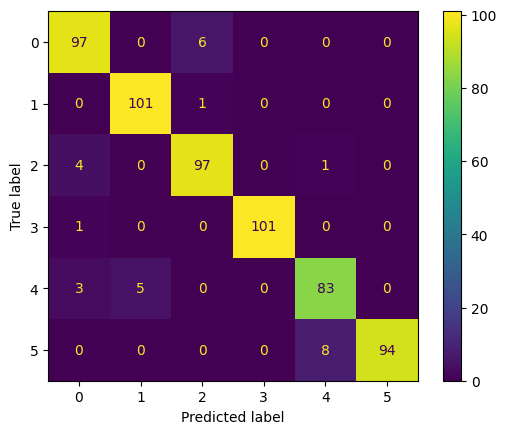

In [58]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [59]:
print(classification_report(labels_test_argmax, classes_x_test))

              precision    recall  f1-score   support

           0       0.92      0.94      0.93       103
           1       0.95      0.99      0.97       102
           2       0.93      0.95      0.94       102
           3       1.00      0.99      1.00       102
           4       0.90      0.91      0.91        91
           5       1.00      0.92      0.96       102

    accuracy                           0.95       602
   macro avg       0.95      0.95      0.95       602
weighted avg       0.95      0.95      0.95       602



In [60]:
""" 
# Real-time prediction loop with plotting
def prepare_data(data,window_size,sensor_data_dim):
  # Assuming data is a continuous stream of sensor readings
  window_xdata = data.iloc[:200,:-1]  # Get the latest window of data
  window_label = data.iloc[:200,-1]
  window_array = window_xdata.values
  window_label_array = window_label.values
  #print(window_array)
  #print(len(window_xdata))
  #print(len(window_xdata))  
  #print(len(window_xdata)) 
  print(window_xdata.shape)
  #print(window_label)
  #window_label_array = window_label_array.reshape(window_label_array.shape[0],1)
  #print(window_label_array.shape)
  #print(window_label_array)
  window_label_array = window_label_array[0]
  print(window_label_array)
  return (window_array.reshape((1, window_size, sensor_data_dim)),window_label_array)  # Reshape for LSTM input """

' \n# Real-time prediction loop with plotting\ndef prepare_data(data,window_size,sensor_data_dim):\n  # Assuming data is a continuous stream of sensor readings\n  window_xdata = data.iloc[:200,:-1]  # Get the latest window of data\n  window_label = data.iloc[:200,-1]\n  window_array = window_xdata.values\n  window_label_array = window_label.values\n  #print(window_array)\n  #print(len(window_xdata))\n  #print(len(window_xdata))  \n  #print(len(window_xdata)) \n  print(window_xdata.shape)\n  #print(window_label)\n  #window_label_array = window_label_array.reshape(window_label_array.shape[0],1)\n  #print(window_label_array.shape)\n  #print(window_label_array)\n  window_label_array = window_label_array[0]\n  print(window_label_array)\n  return (window_array.reshape((1, window_size, sensor_data_dim)),window_label_array)  # Reshape for LSTM input '

In [61]:
""" def prepare_data(test_data,window_size,sensor_data_dim):
  # Assuming data is a continuous stream of sensor readings
  window_xdata = test_data.iloc[:200,:-1]  # Get the latest window of data
  window_label = test_data.iloc[:200,-1]
  window_array = window_xdata.values
  window_label_array = window_label.values  
  print(window_xdata.shape)
  window_label_array = window_label_array[0]
  print(window_label_array)
  return (window_array.reshape((1, window_size, sensor_data_dim)),window_label_array)  # Reshape for LSTM input

# Real-time prediction loop with plotting
ground_truth = []  # List to store true activity labels
predicted_activities = []  # List to store predicted activity labels
colors = ['green', 'red']  # Green for correct, red for incorrect

count = 0
while not X_test_data.empty and X_test_data.shape[0]>199:
  count = count + 1
  new_xdata, true_activity_label = prepare_data(X_test_data,200,6)
  prediction = lstm_model.predict(new_xdata)
  predicted_activity = np.argmax(prediction[0])  # Get the class with highest probability
  ground_truth.append(true_activity_label)  # Store true label
  predicted_activities.append(predicted_activity)
  colors = ['red' if pred != true_val else 'green' for pred, true_val in zip(predicted_activities, ground_truth)]

  # Prepare data for scatter plot (assuming multiple data points per time step)
  x_data = range(len(predicted_activities))  # Time steps
  y_data = predicted_activities  # Predicted activities (can be modified for other dimensions)
  

  if 1 <= count <= 50:
    # Create the scatter plot with optional error bars (consider for uncertainty visualization)
    plt.figure(figsize=(12, 8))  # Adjust figure size as needed
    plt.scatter(x_data, y_data, marker='o', c = colors)  # Default green for prediction
    # plt.errorbar(x_data, y_data, yerr=error_bars, fmt='o', capsize=5, color=colors[0])  # Uncomment for error bars

    # Update plot with true label if available (consider different color/marker)
    #if true_activity_label is not None:
      #plt.scatter(count, true_activity_label, marker='s', color=colors[1], label='True Label')  # Red for true label (optional)

    plt.xlabel("Time Step")
    plt.ylabel("Activity (or other relevant dimension)")  # Adjust label based on data
    plt.ylim(-1, 6)  # Adjust y-axis based on number of activity classes (or data range)
    plt.title("Real-time Activity Predictions")
    plt.legend() if true_activity_label is not None else None  # Show legend if true label is displayed
    plt.pause(0.1)  # Adjust pause time for smoother visualization

    plt.ion()
    plt.show()

    # Clear plot for next iteration or consider animation for smoother transition
    plt.clf() 
  X_test_data = X_test_data.iloc[200:]
  print(f"contando {count}") """



' def prepare_data(test_data,window_size,sensor_data_dim):\n  # Assuming data is a continuous stream of sensor readings\n  window_xdata = test_data.iloc[:200,:-1]  # Get the latest window of data\n  window_label = test_data.iloc[:200,-1]\n  window_array = window_xdata.values\n  window_label_array = window_label.values  \n  print(window_xdata.shape)\n  window_label_array = window_label_array[0]\n  print(window_label_array)\n  return (window_array.reshape((1, window_size, sensor_data_dim)),window_label_array)  # Reshape for LSTM input\n\n# Real-time prediction loop with plotting\nground_truth = []  # List to store true activity labels\npredicted_activities = []  # List to store predicted activity labels\ncolors = [\'green\', \'red\']  # Green for correct, red for incorrect\n\ncount = 0\nwhile not X_test_data.empty and X_test_data.shape[0]>199:\n  count = count + 1\n  new_xdata, true_activity_label = prepare_data(X_test_data,200,6)\n  prediction = lstm_model.predict(new_xdata)\n  predicte

(200, 6)
(200,)
0
1/1 [==============================] - 0s 29ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


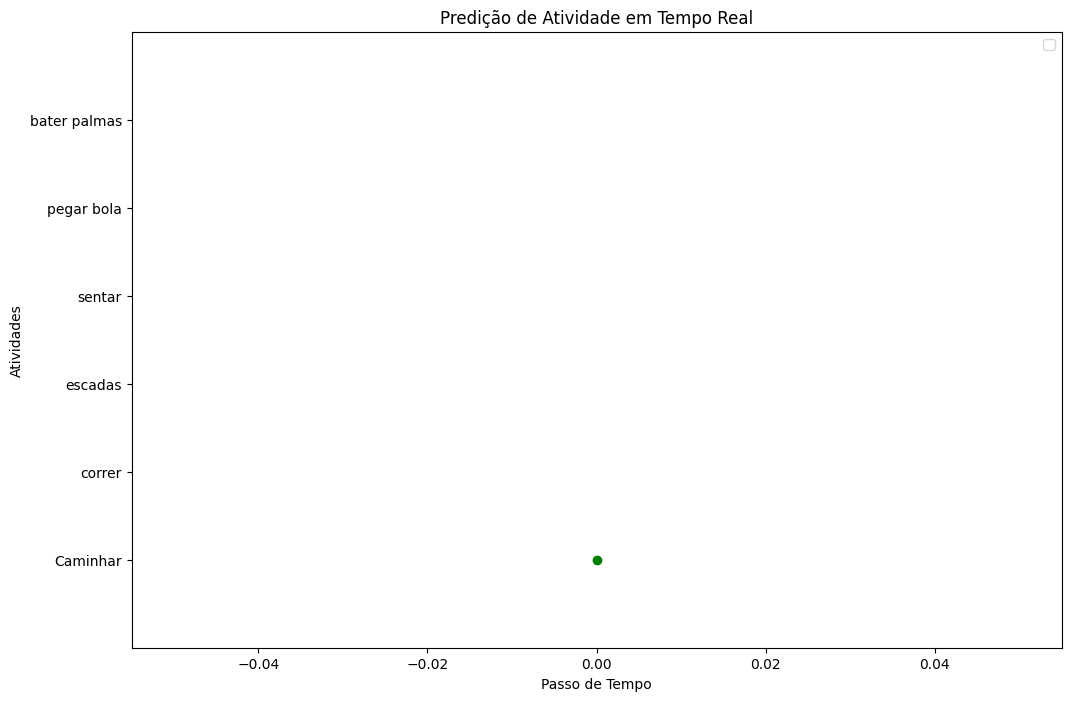

contando 1
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

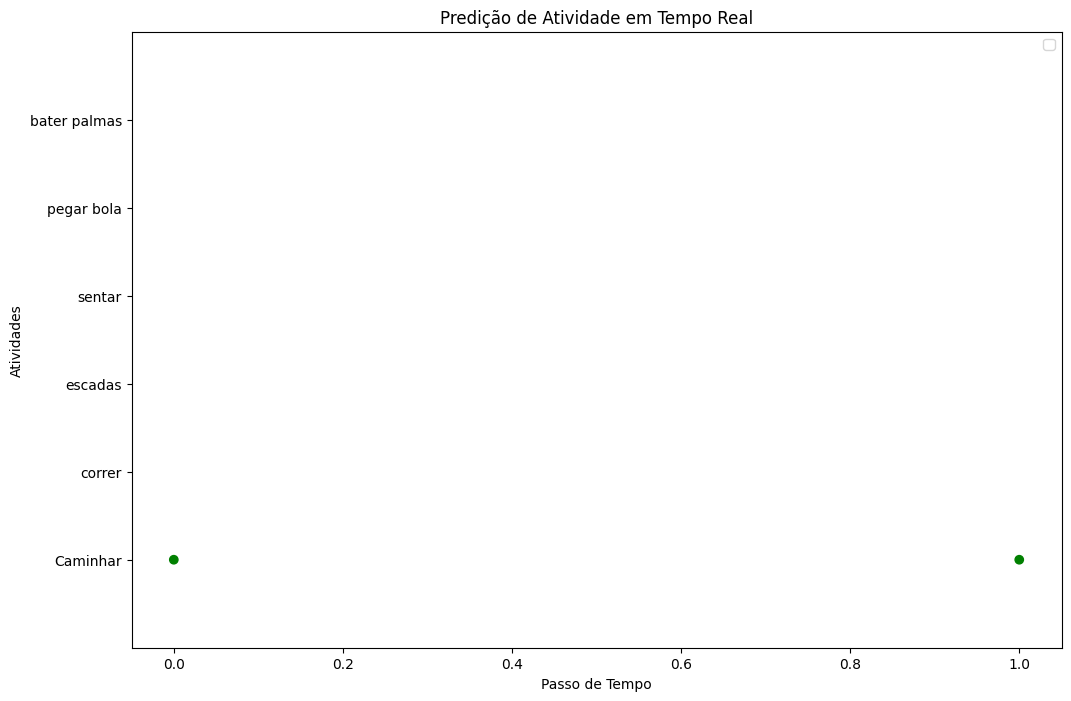

contando 2
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

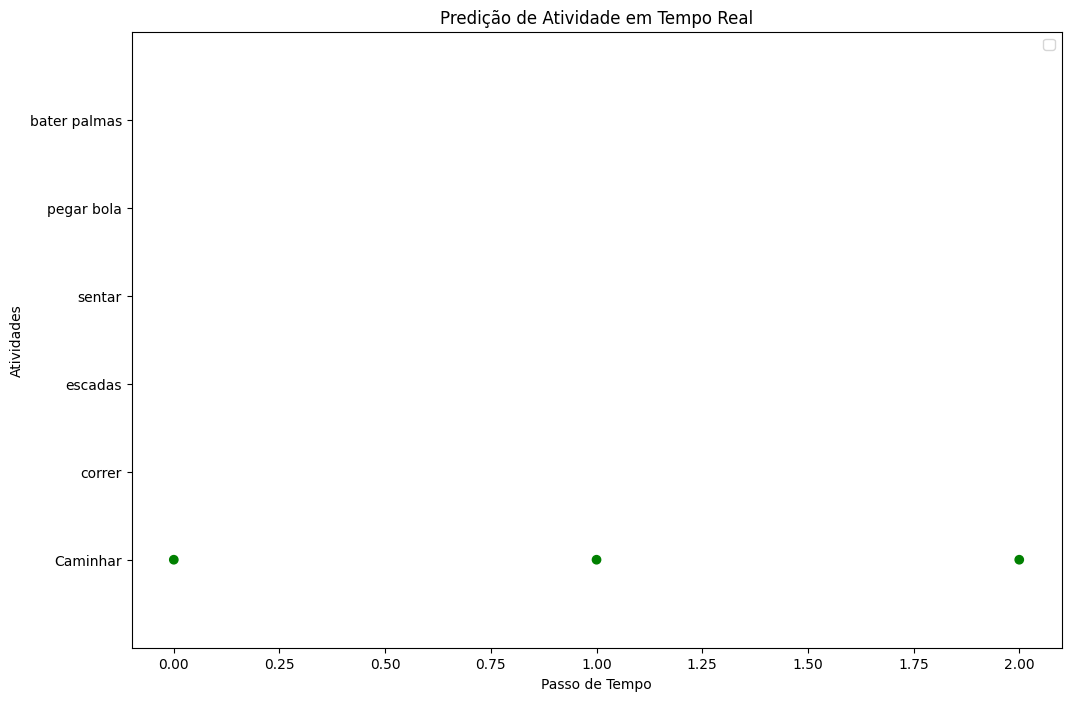

contando 3
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

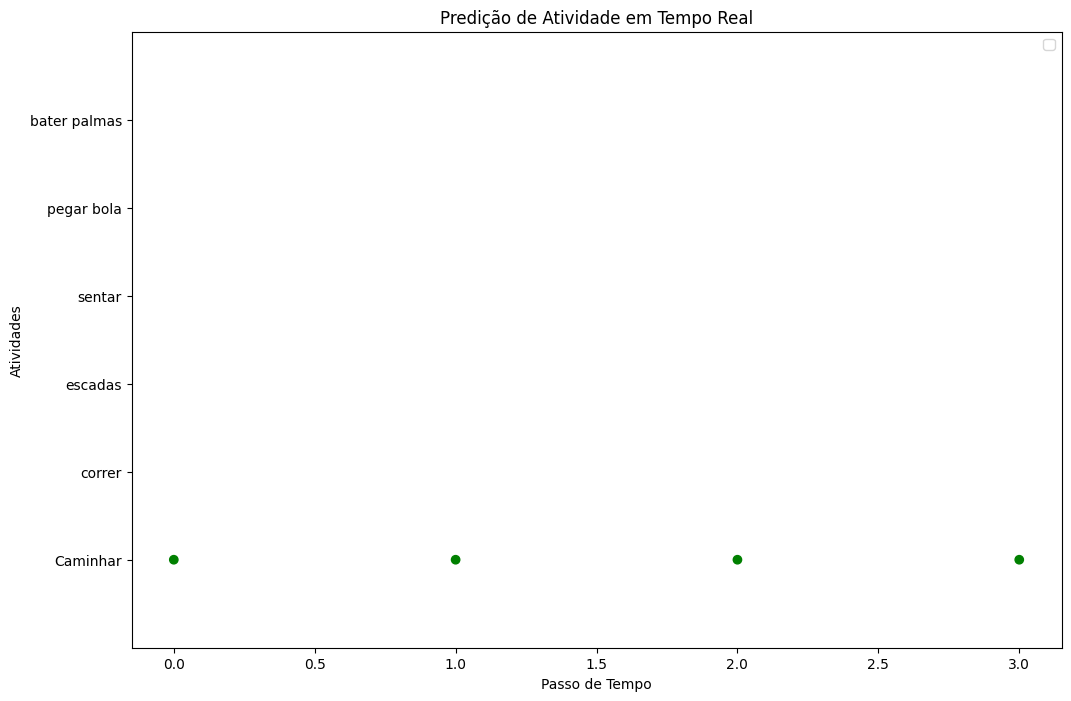

contando 4
(200, 6)
(200,)
0
1/1 [==============================] - 0s 21ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

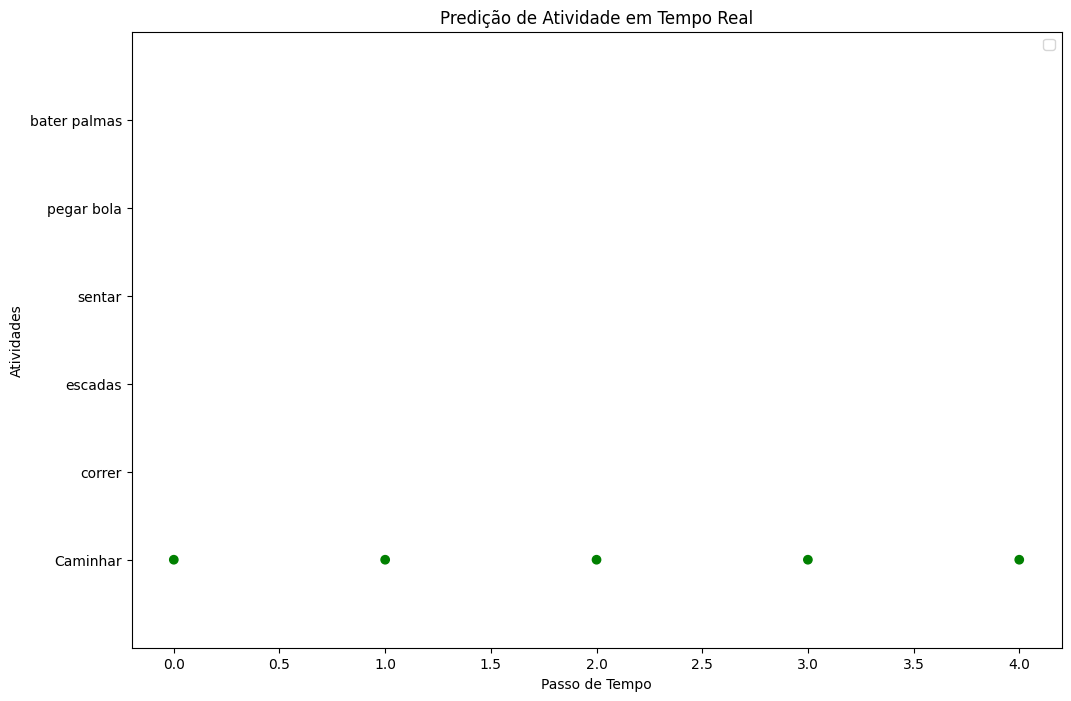

contando 5
(200, 6)
(200,)
0
1/1 [==============================] - 0s 24ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

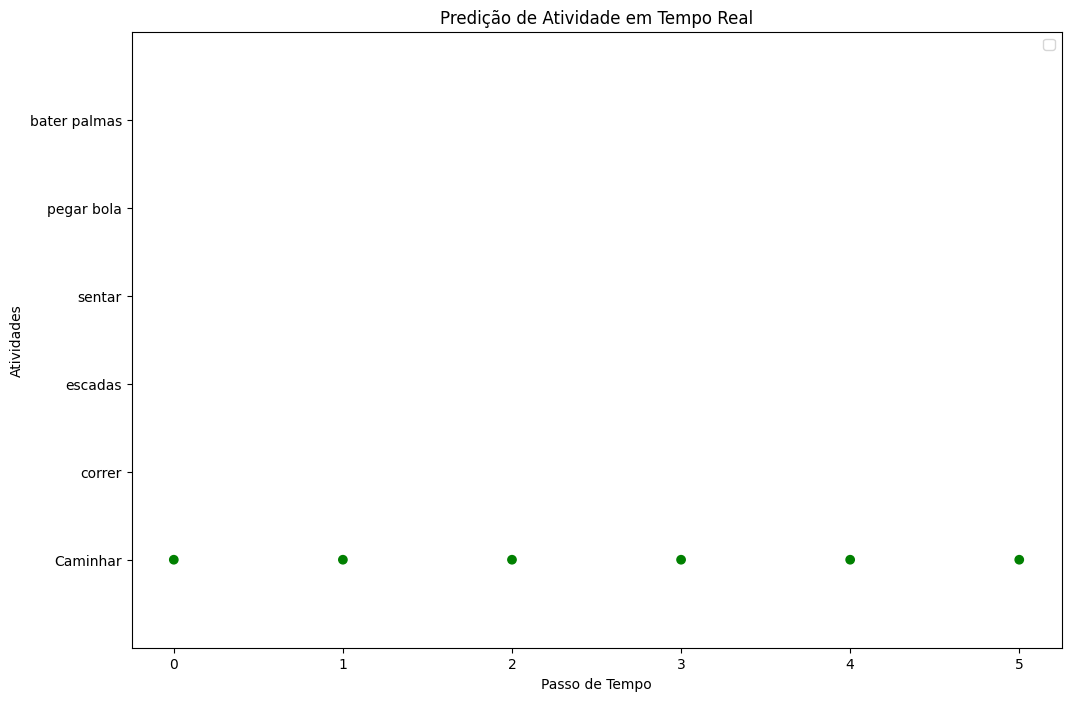

contando 6
(200, 6)
(200,)
0
1/1 [==============================] - 0s 24ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

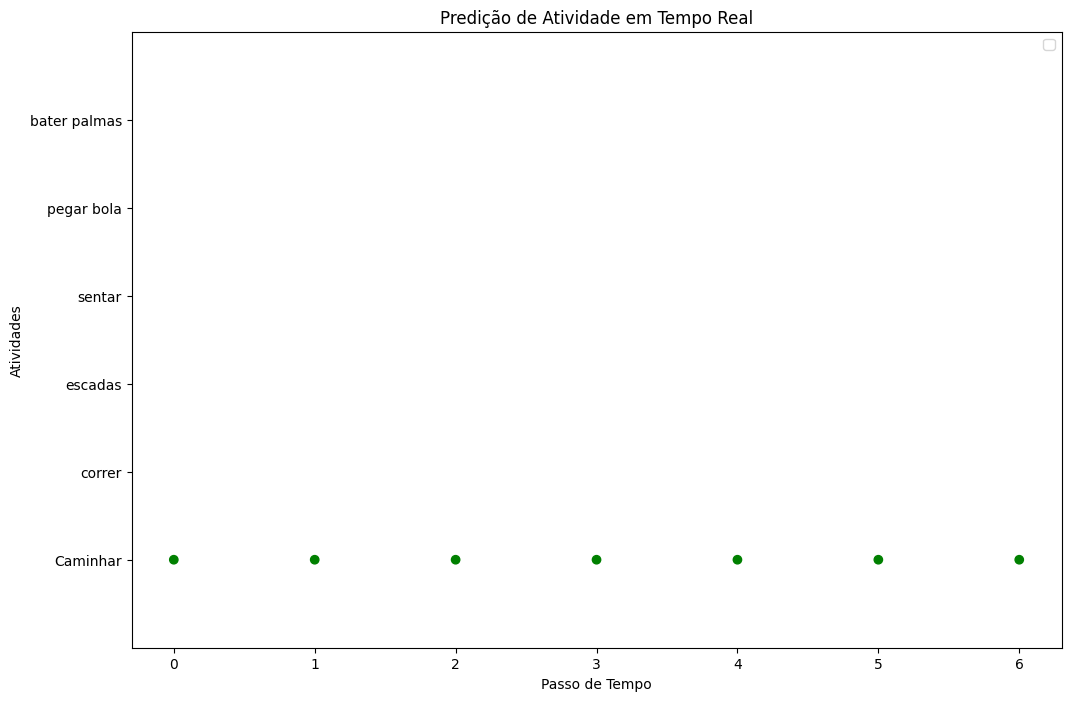

contando 7
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

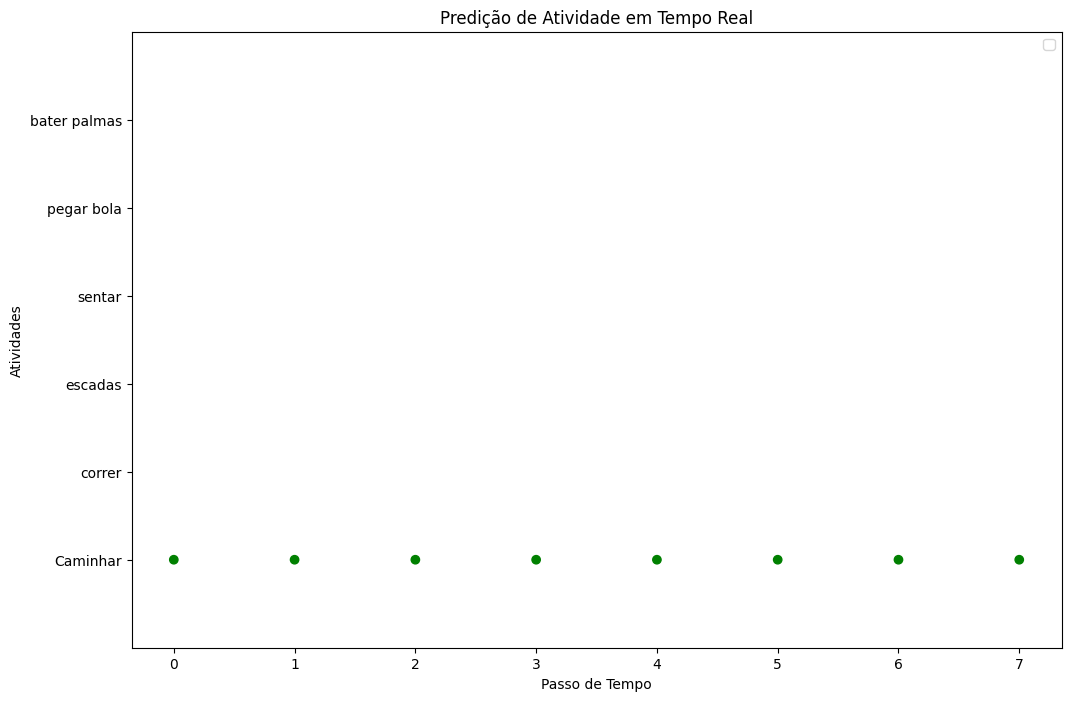

contando 8
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

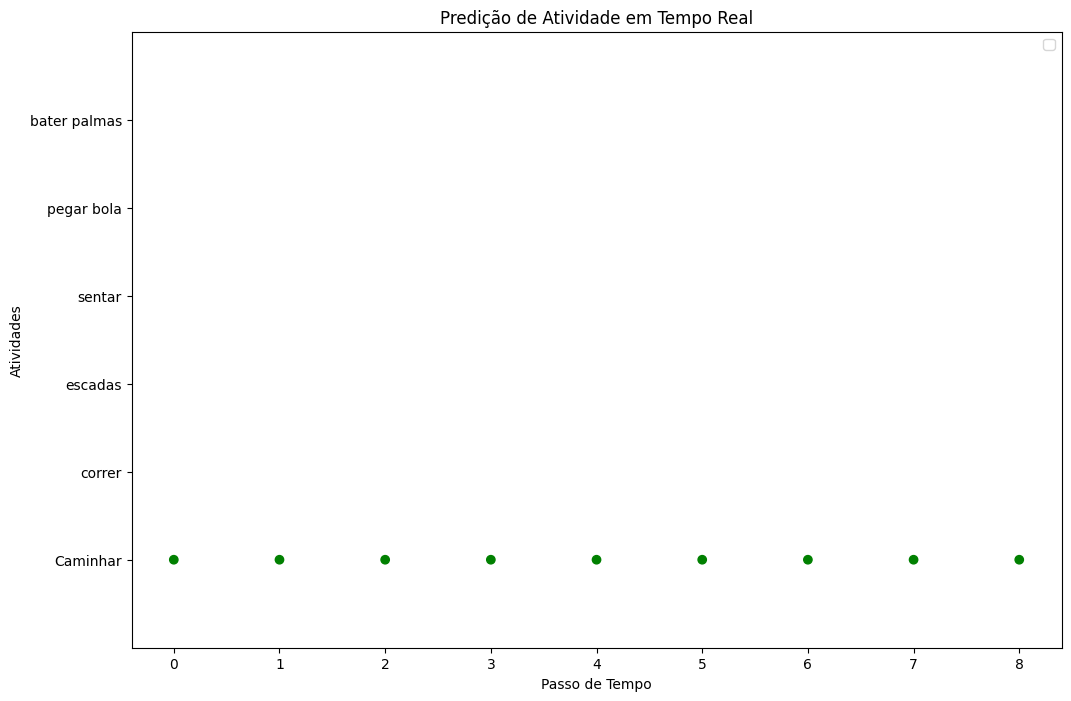

contando 9
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

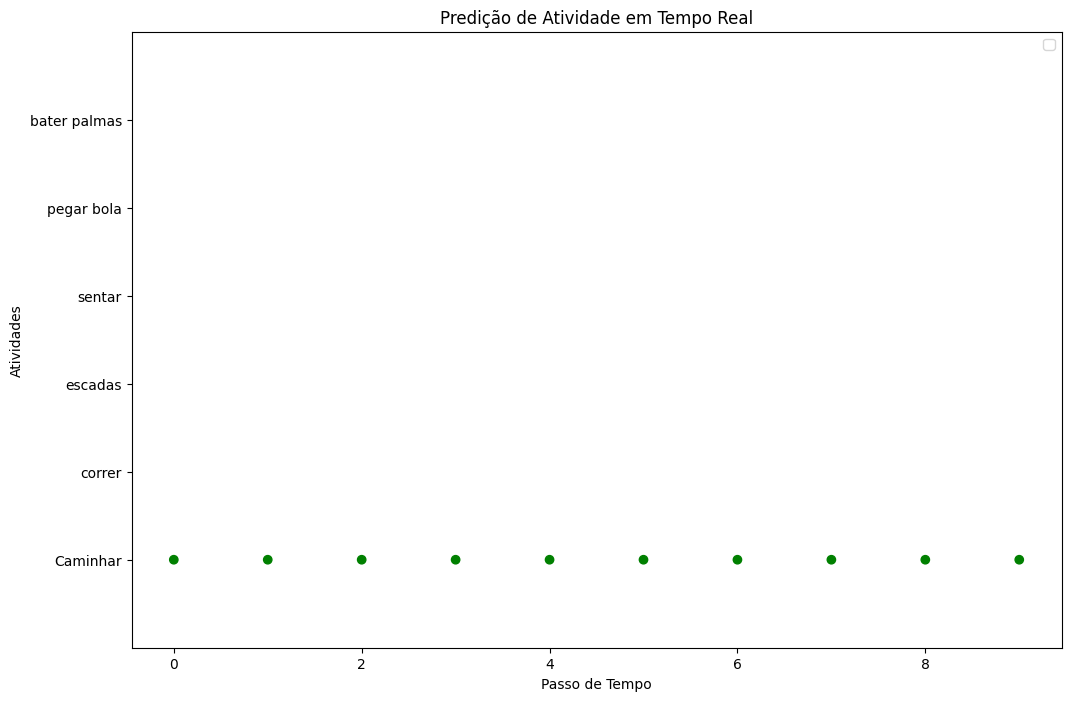

contando 10
(200, 6)
(200,)
0
1/1 [==============================] - 0s 21ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

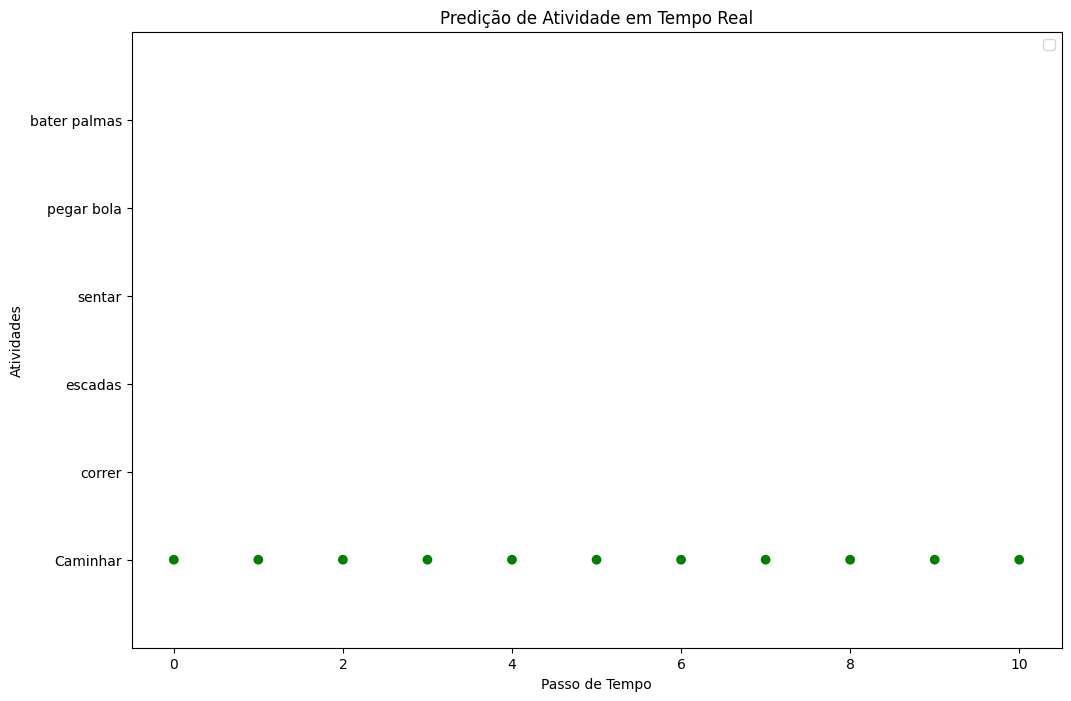

contando 11
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

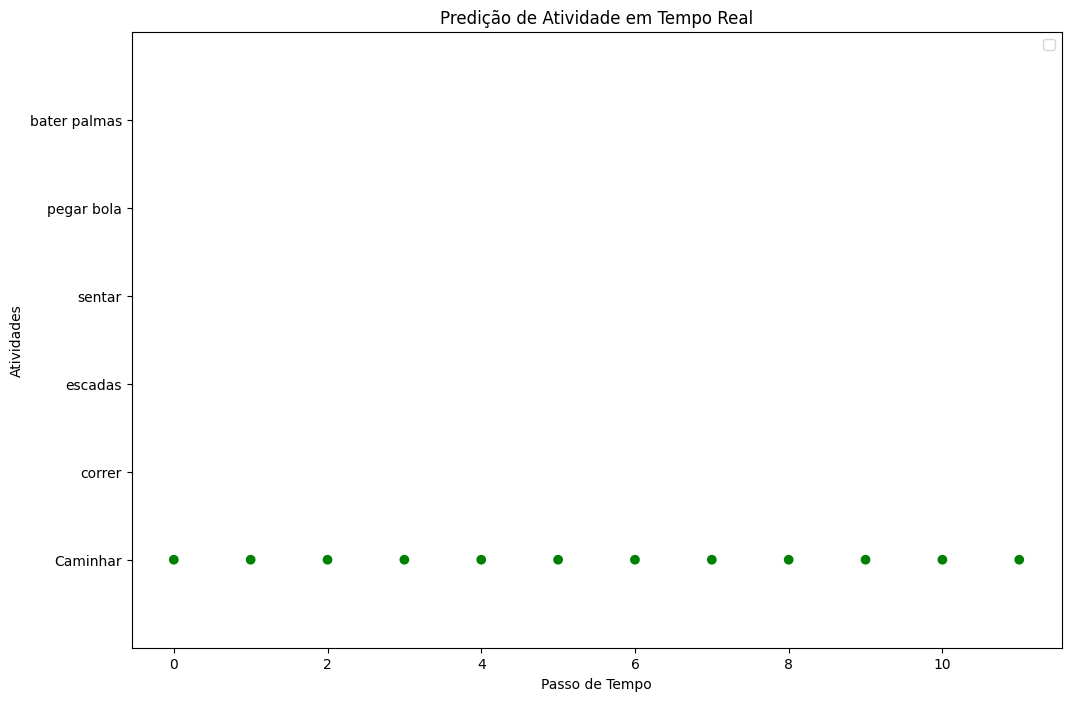

contando 12
(200, 6)
(200,)
0
1/1 [==============================] - 0s 24ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

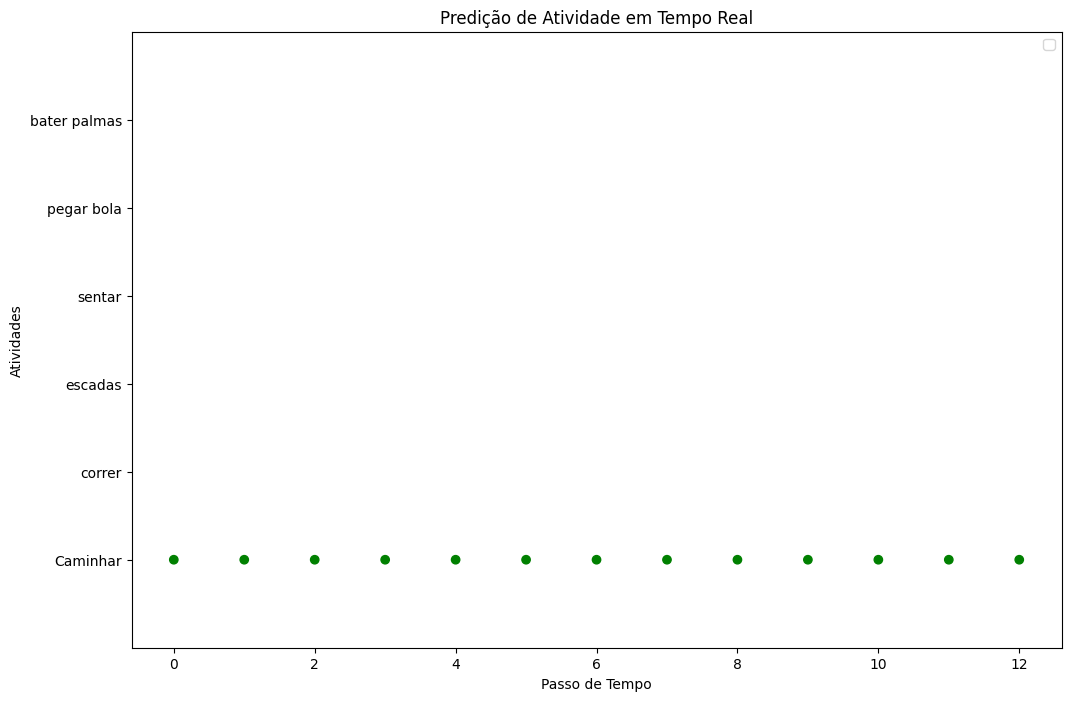

contando 13
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

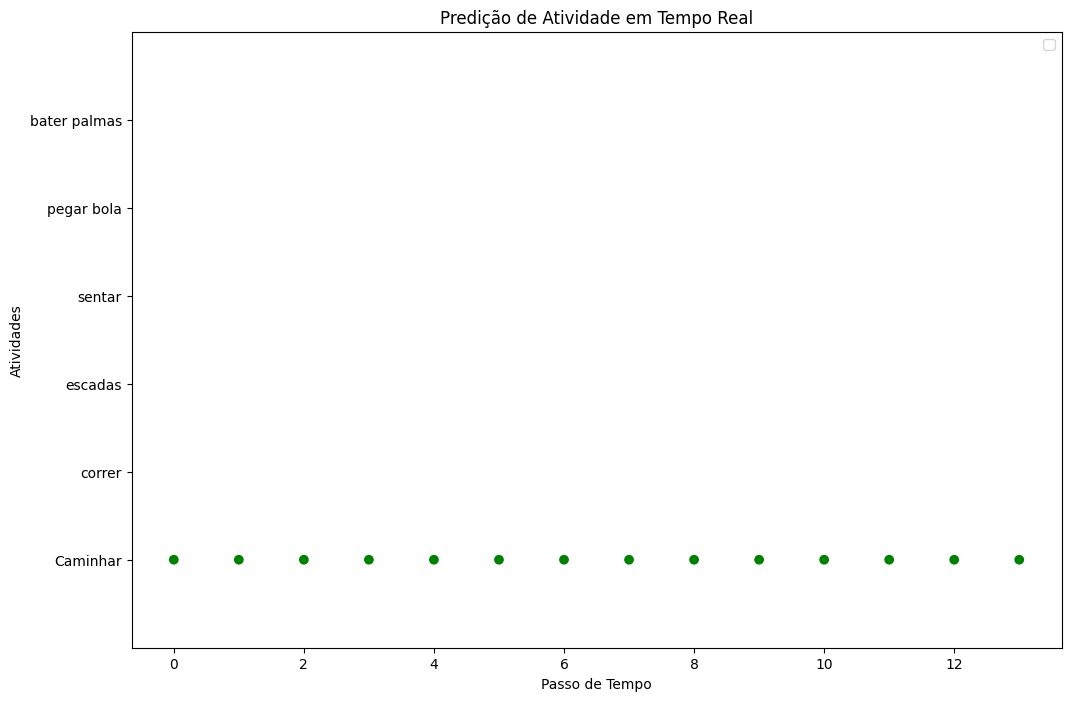

contando 14
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

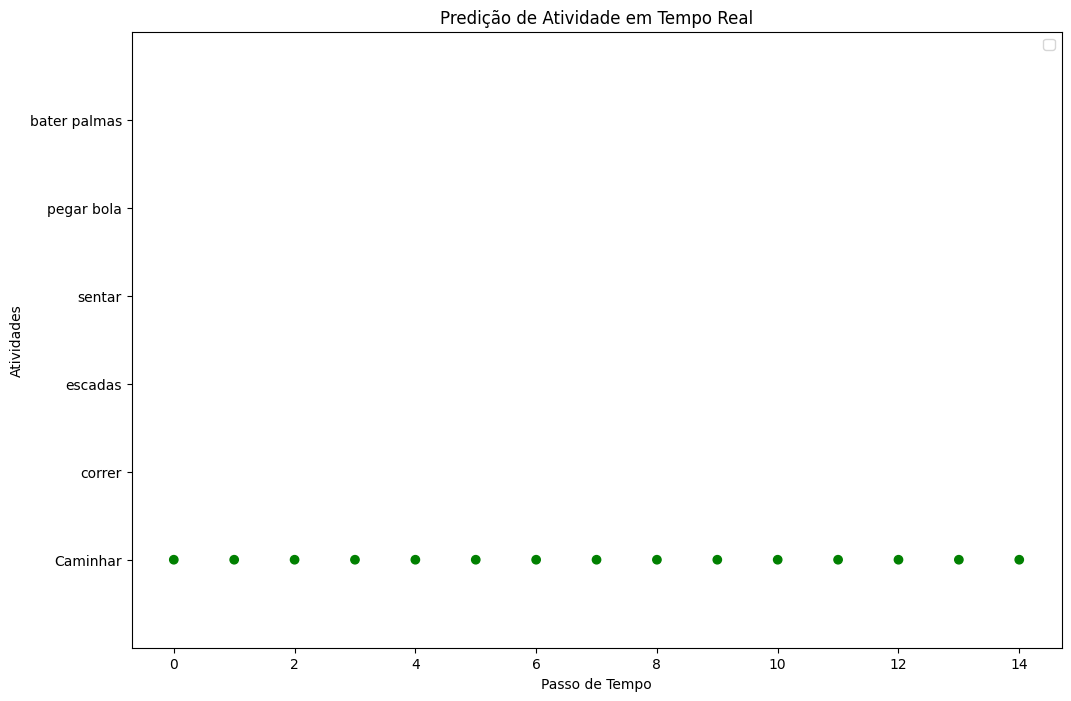

contando 15
(200, 6)
(200,)
0
1/1 [==============================] - 0s 24ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

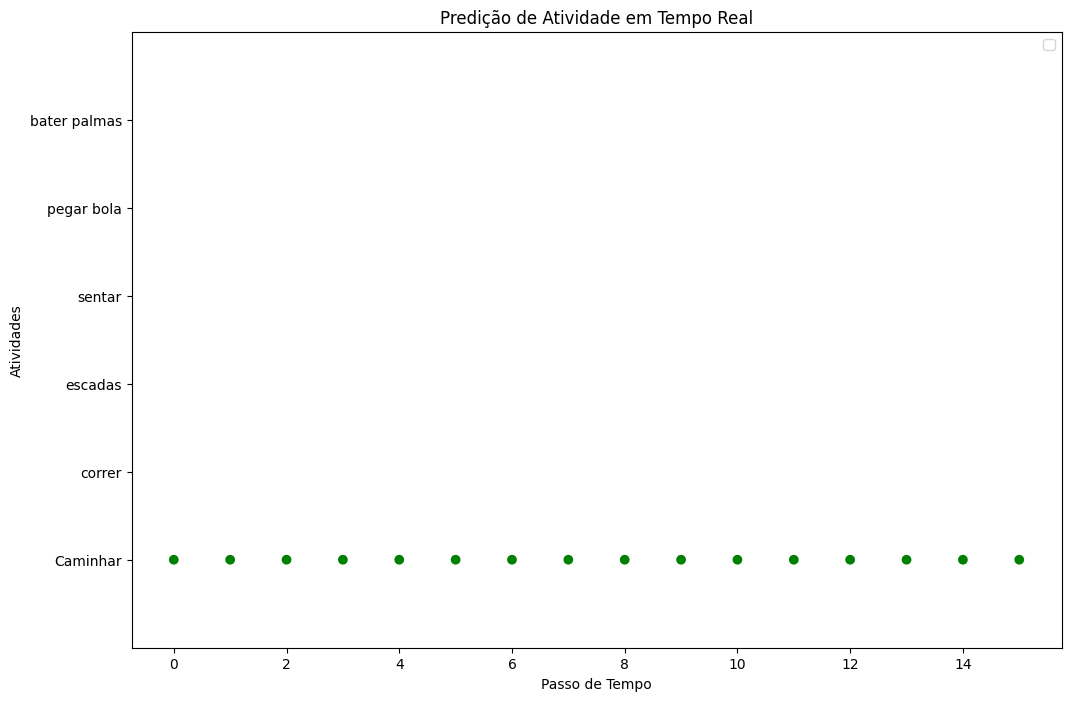

contando 16
(200, 6)
(200,)
0
1/1 [==============================] - 0s 24ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

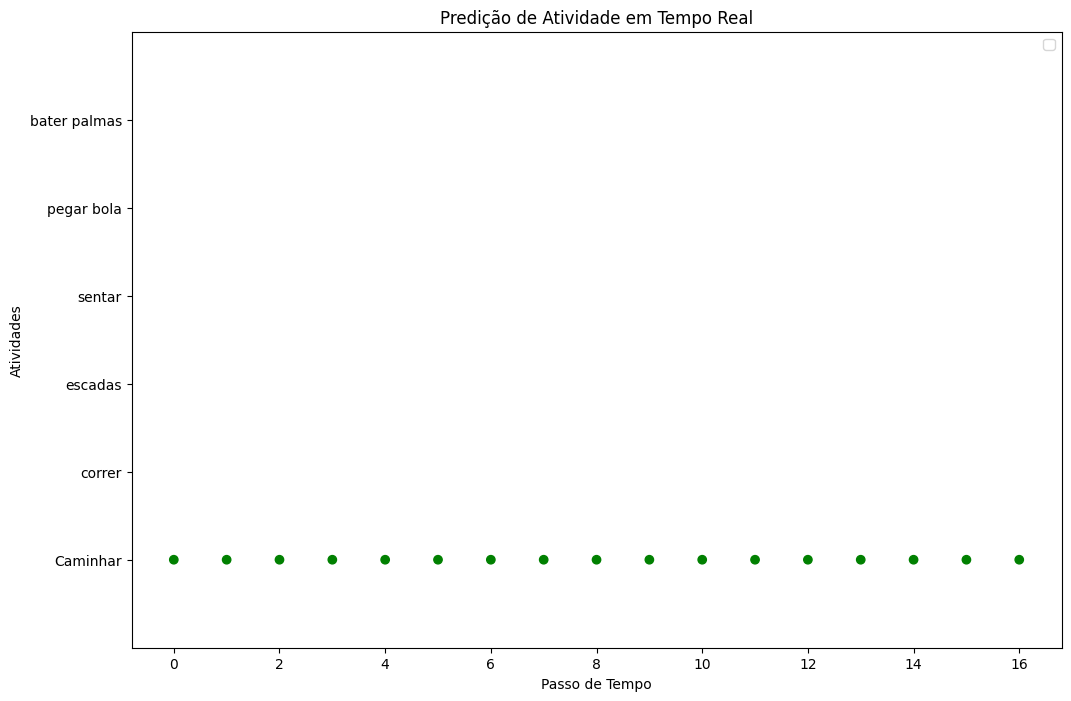

contando 17
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

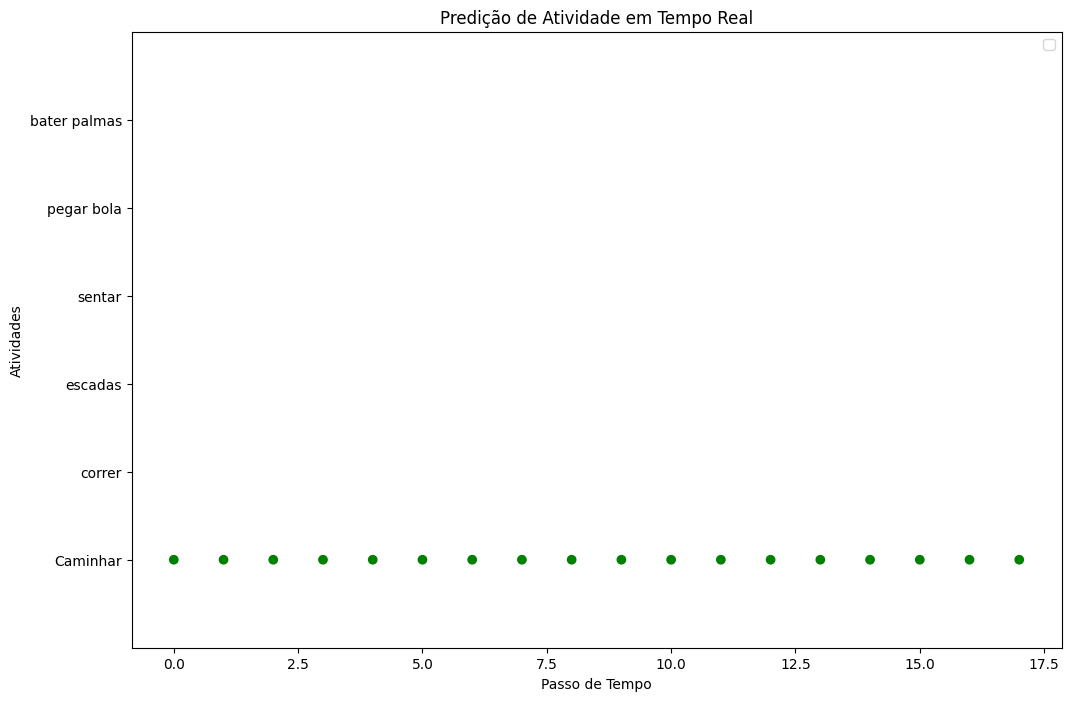

contando 18
(200, 6)
(200,)
0
1/1 [==============================] - 0s 24ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

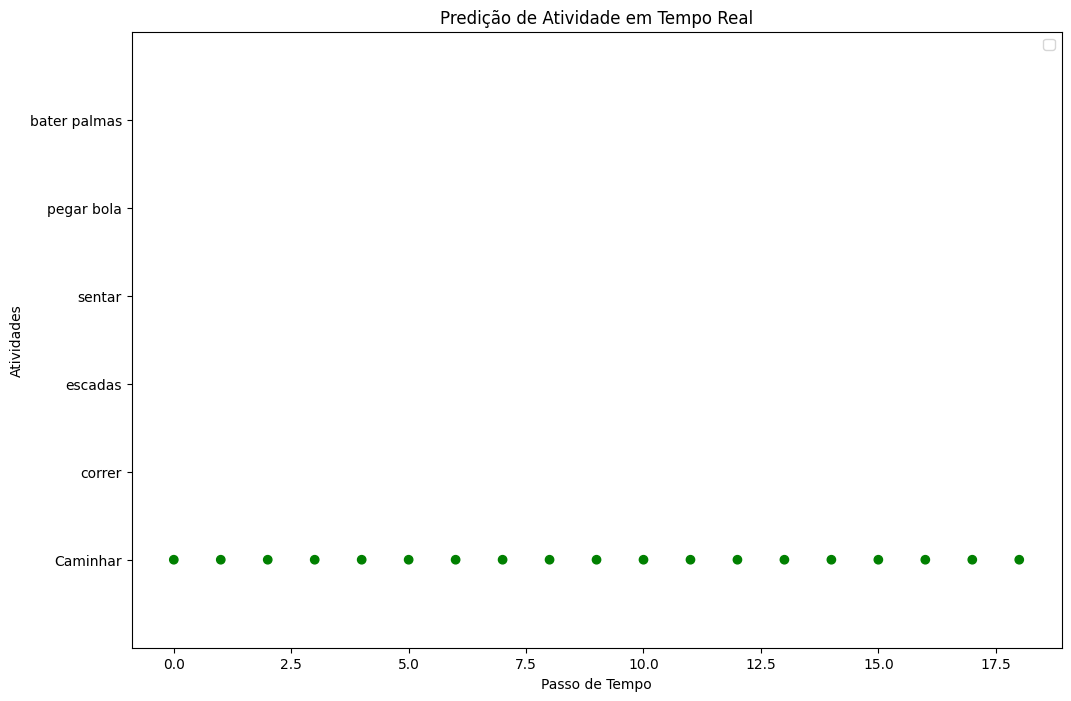

contando 19
(200, 6)
(200,)
0
1/1 [==============================] - 0s 24ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

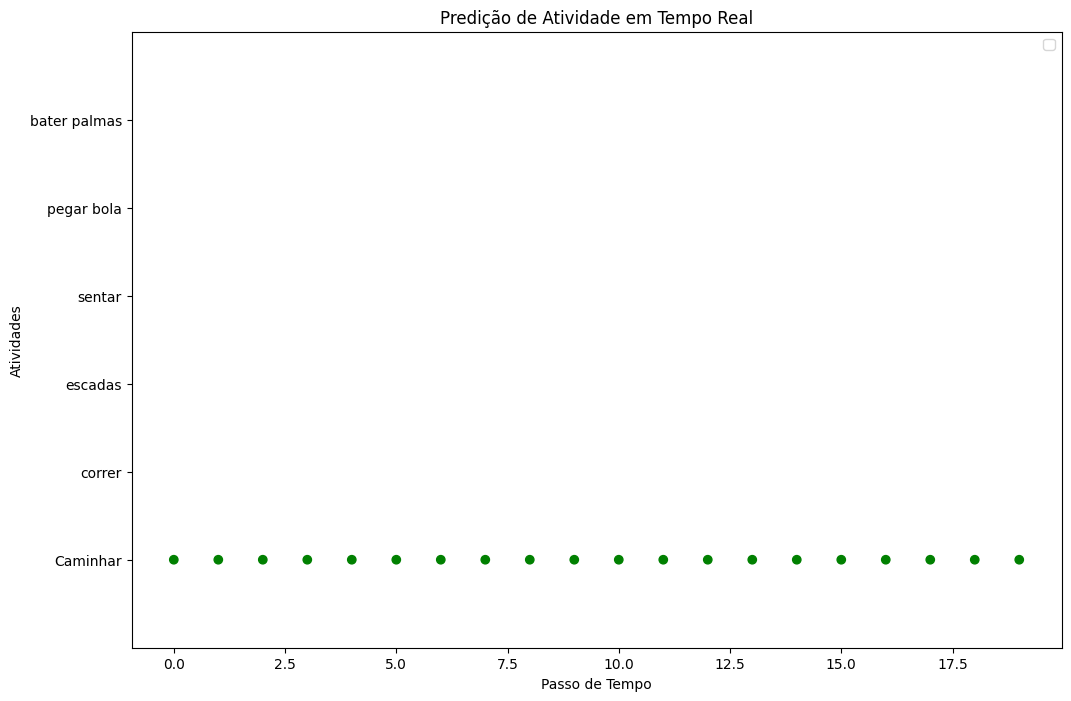

contando 20
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

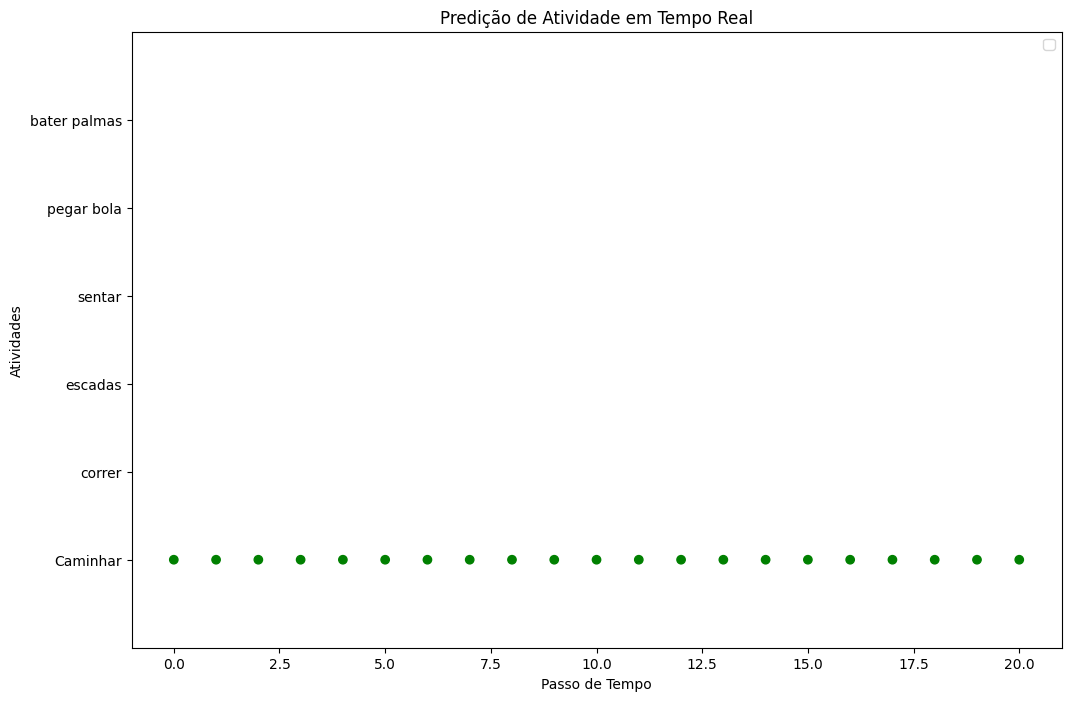

contando 21
(200, 6)
(200,)
0
1/1 [==============================] - 0s 25ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

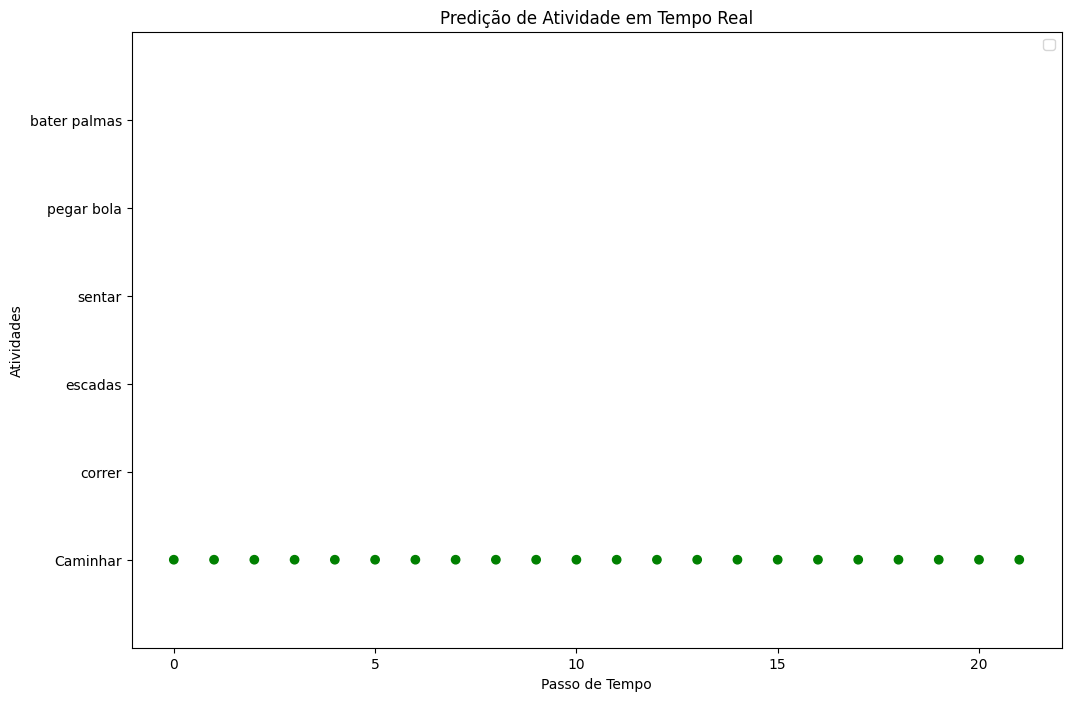

contando 22
(200, 6)
(200,)
0
1/1 [==============================] - 0s 25ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

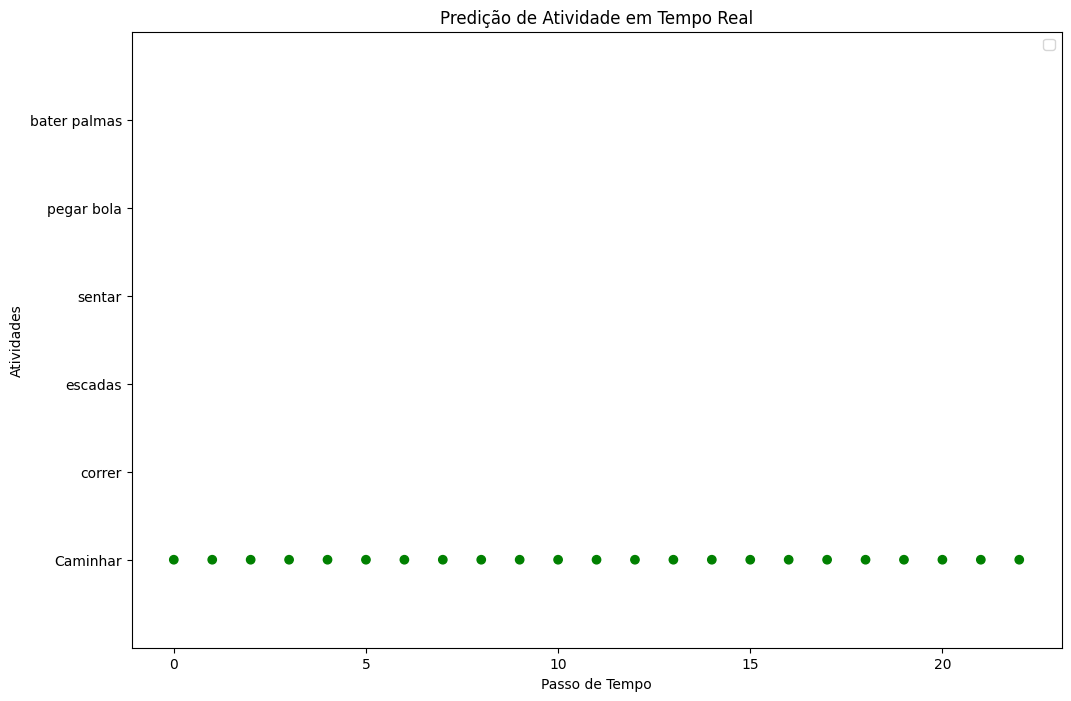

contando 23
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

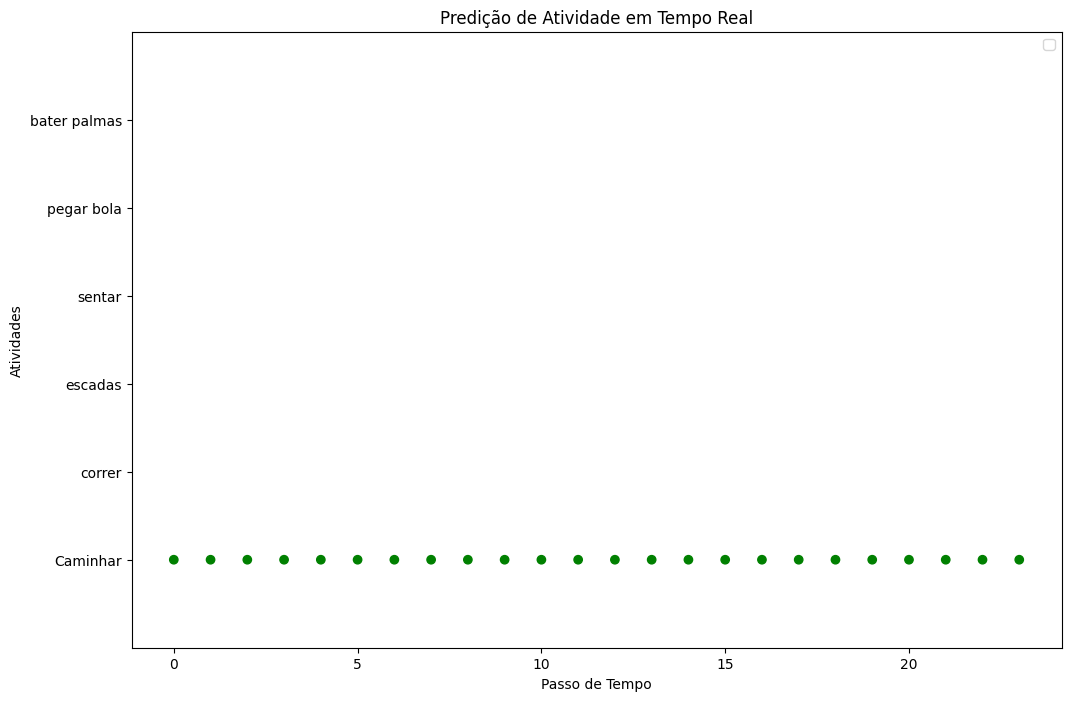

contando 24
(200, 6)
(200,)
0
1/1 [==============================] - 0s 21ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

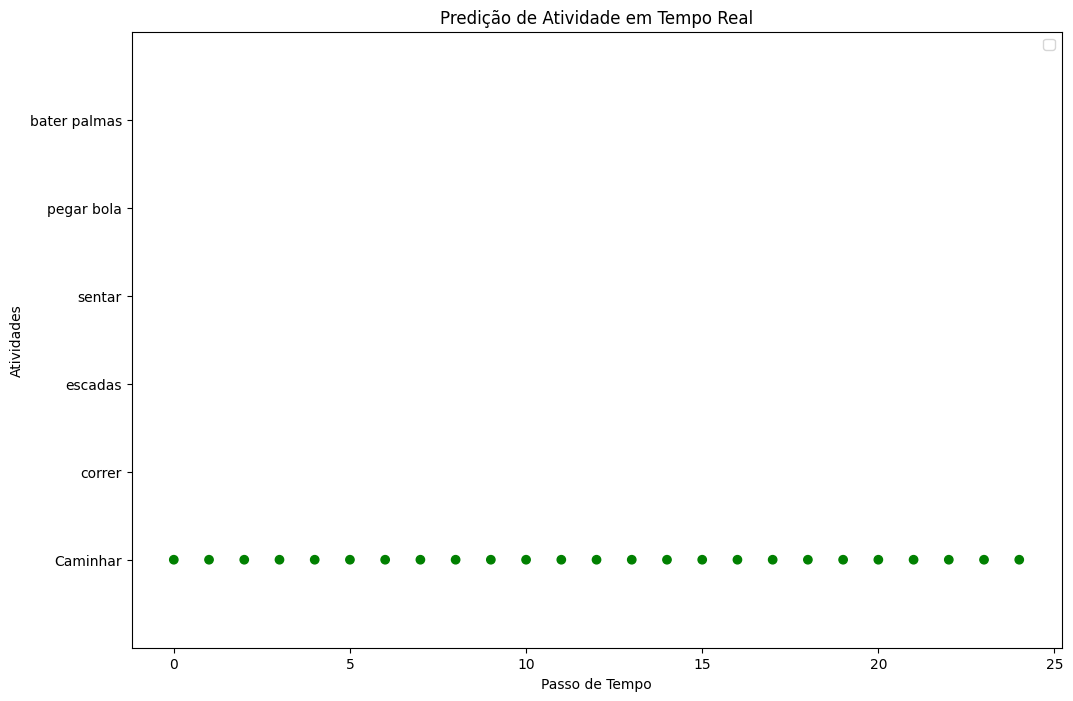

contando 25
(200, 6)
(200,)
0
1/1 [==============================] - 0s 24ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

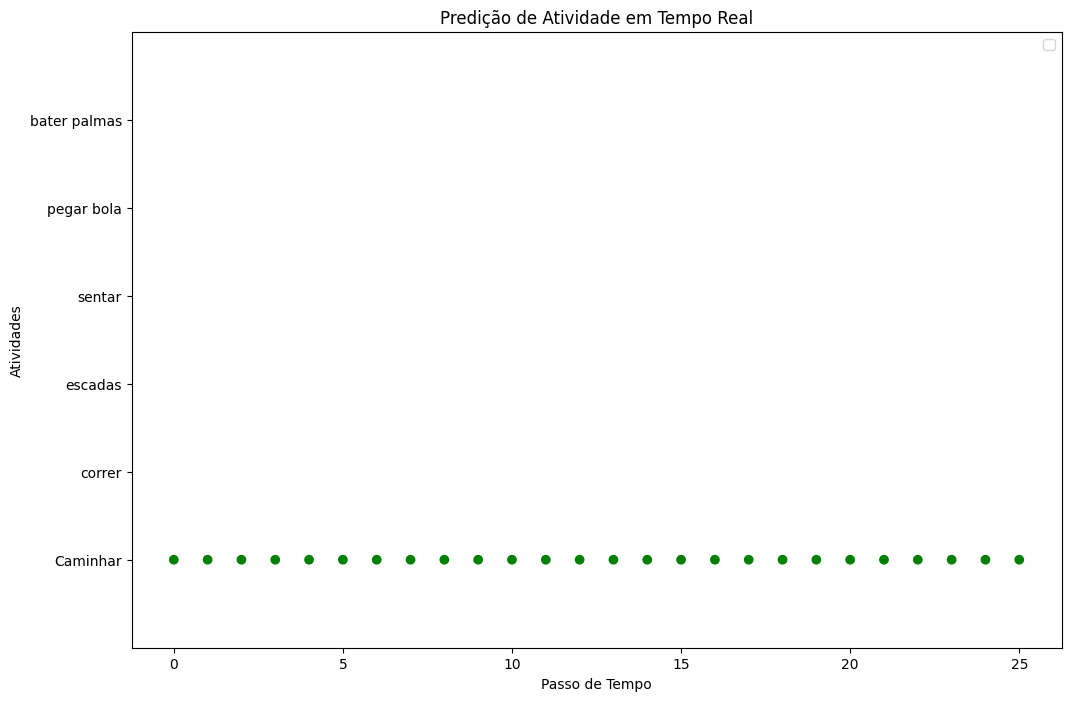

contando 26
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

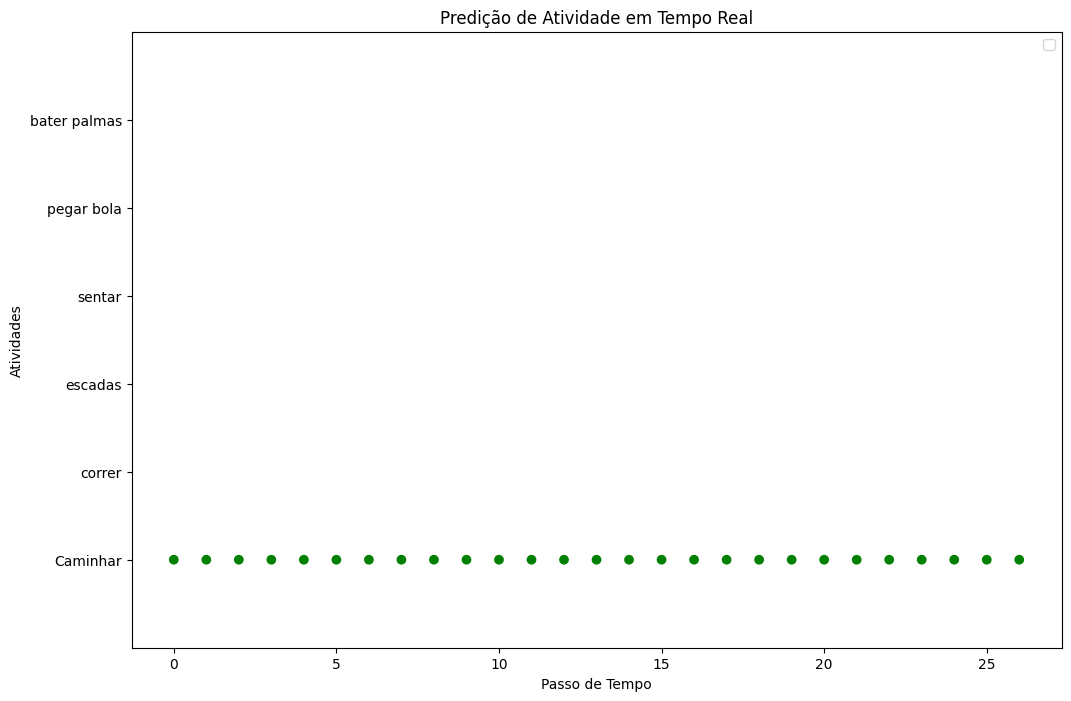

contando 27
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

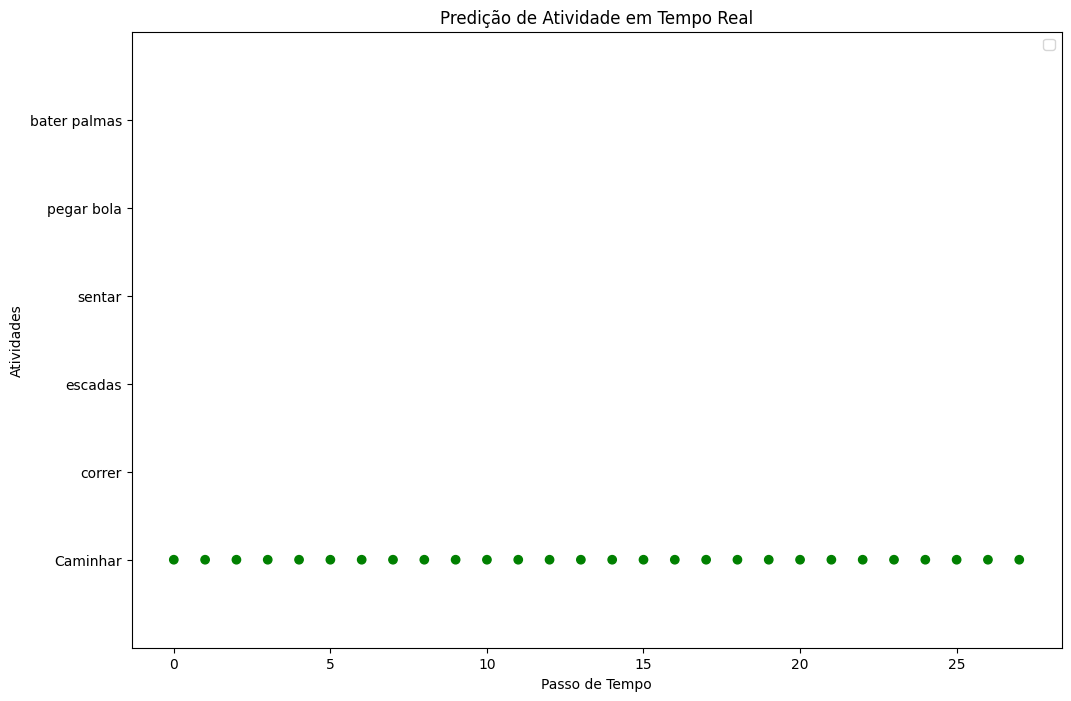

contando 28
(200, 6)
(200,)
0
1/1 [==============================] - 0s 21ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

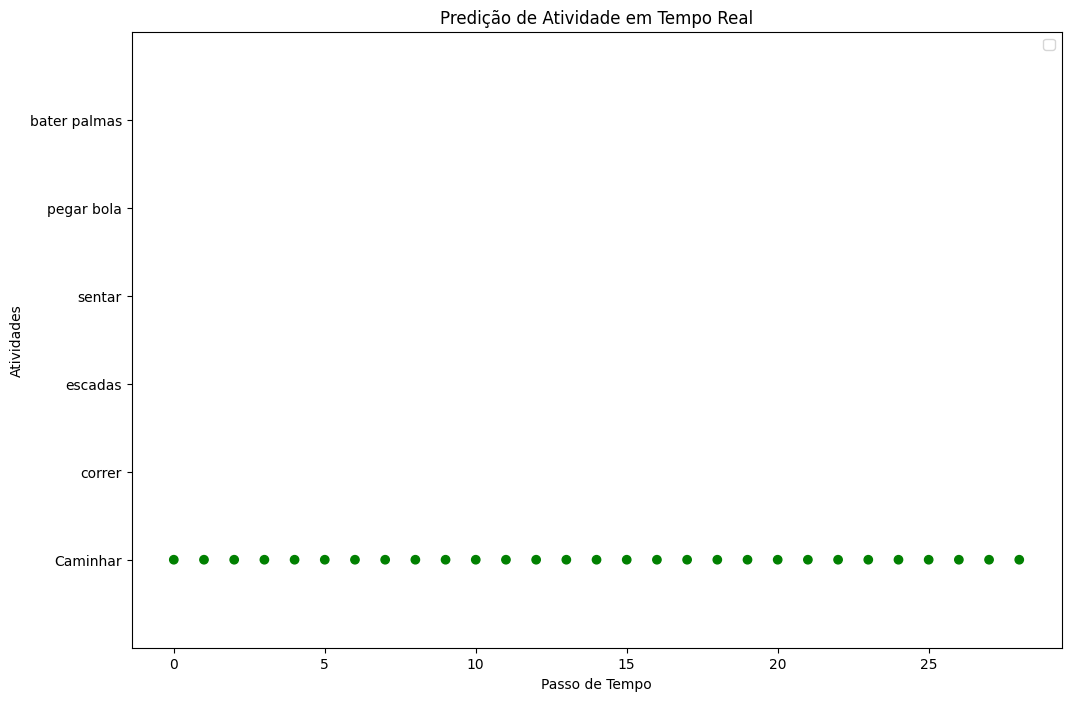

contando 29
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

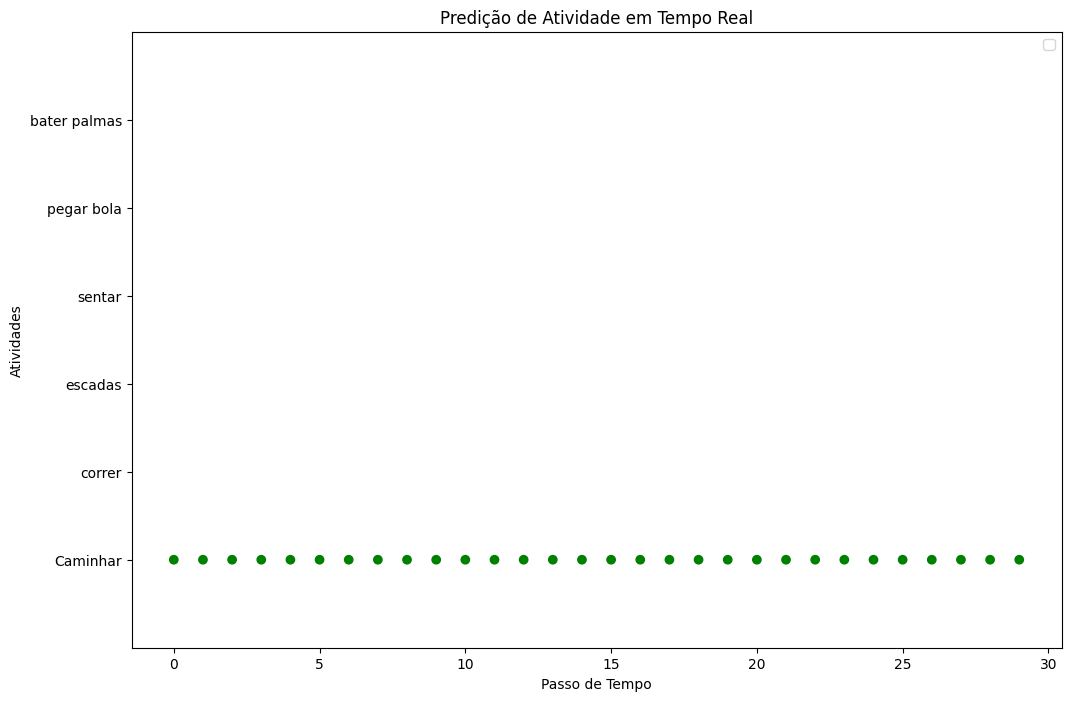

contando 30
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

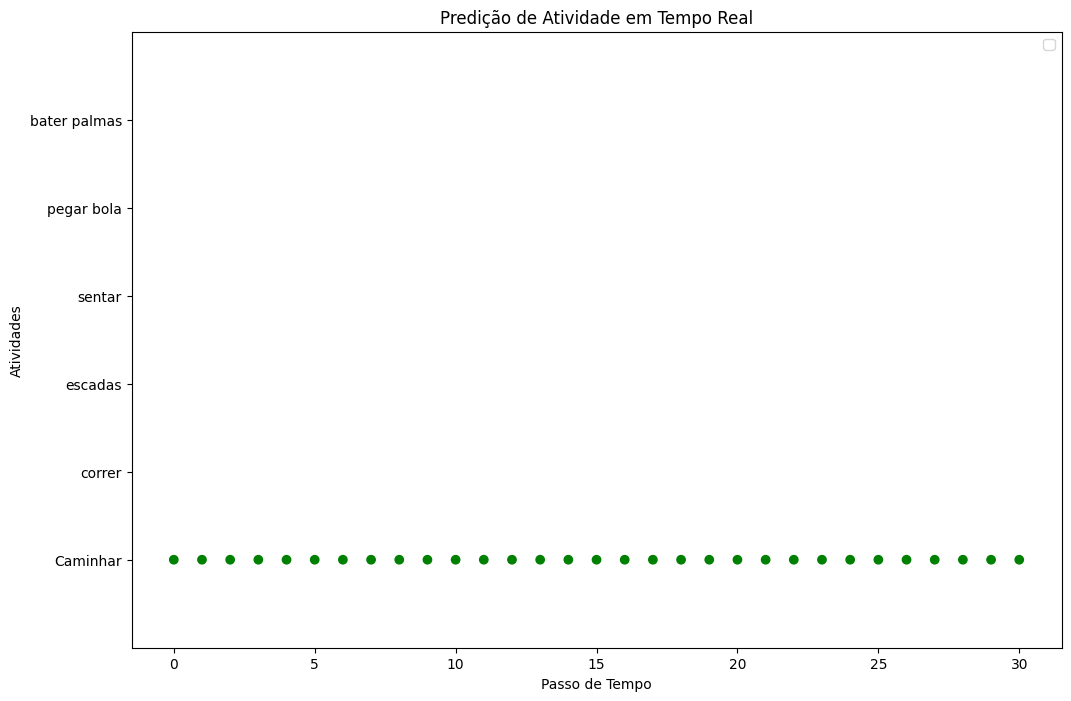

contando 31
(200, 6)
(200,)
0
1/1 [==============================] - 0s 21ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

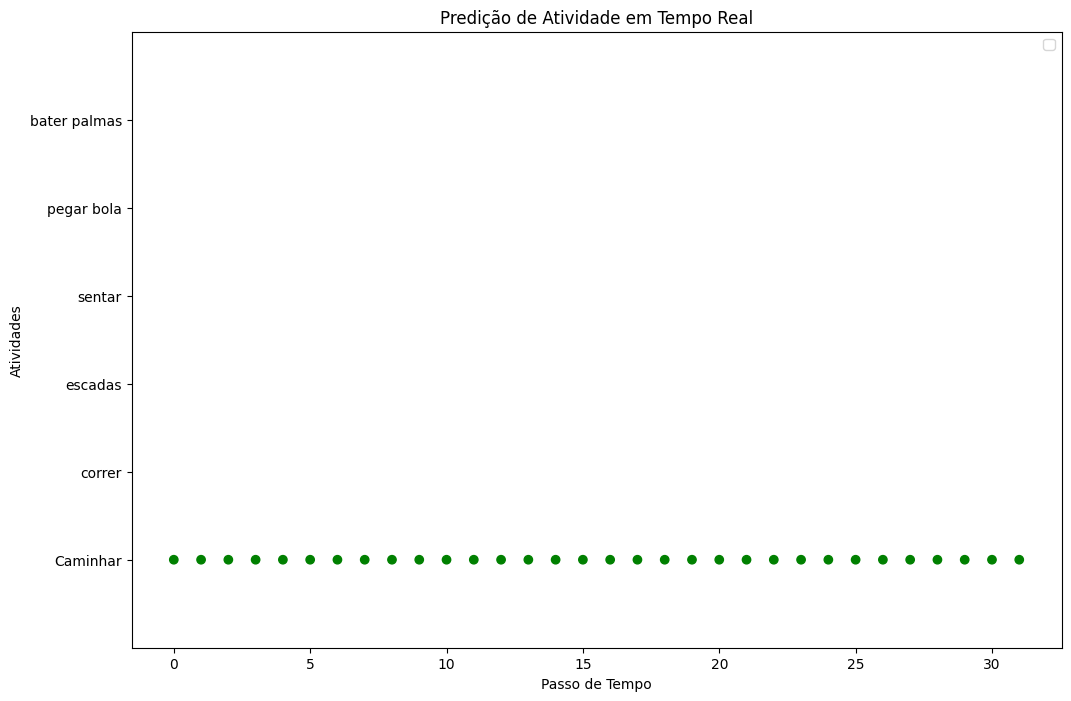

contando 32
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

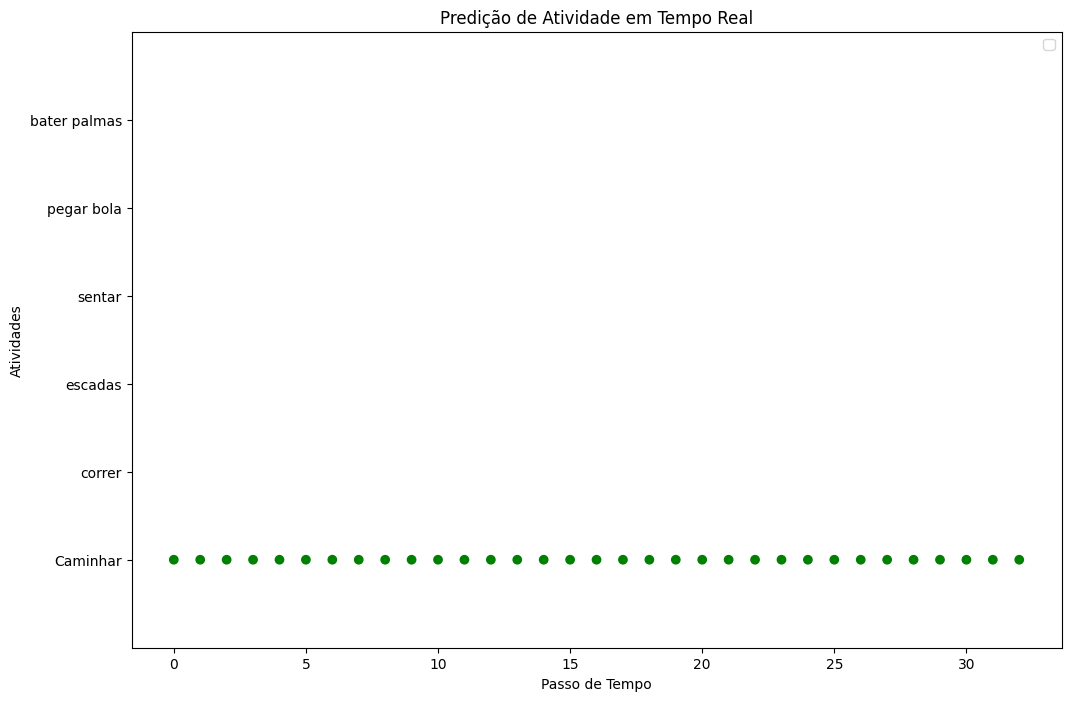

contando 33
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

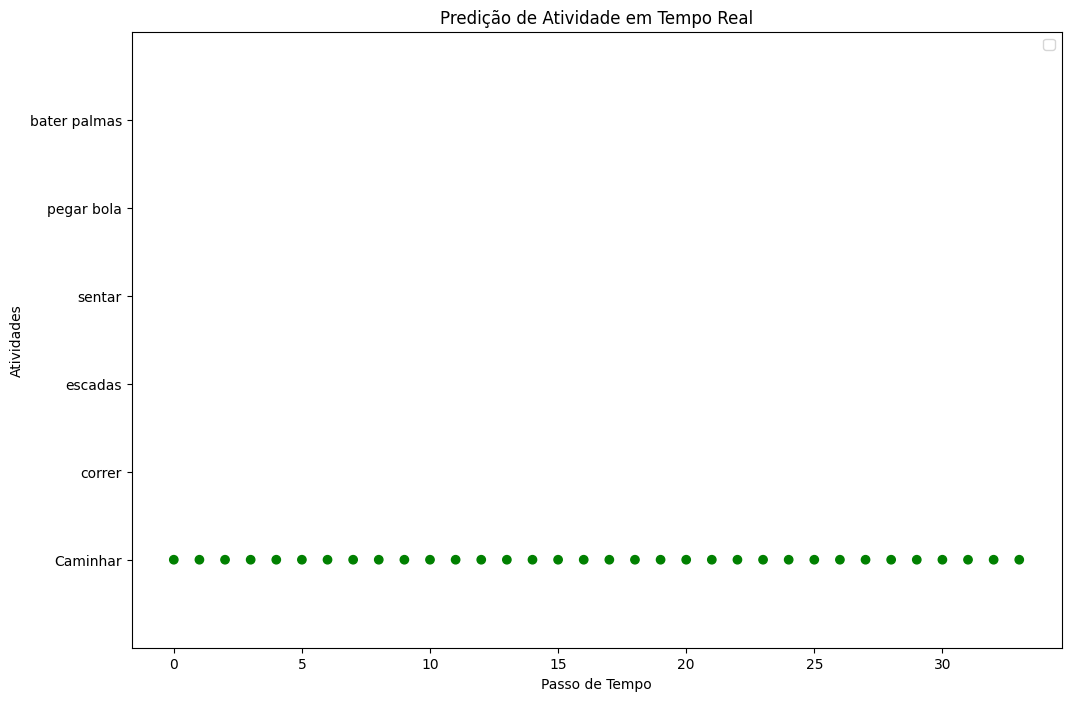

contando 34
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

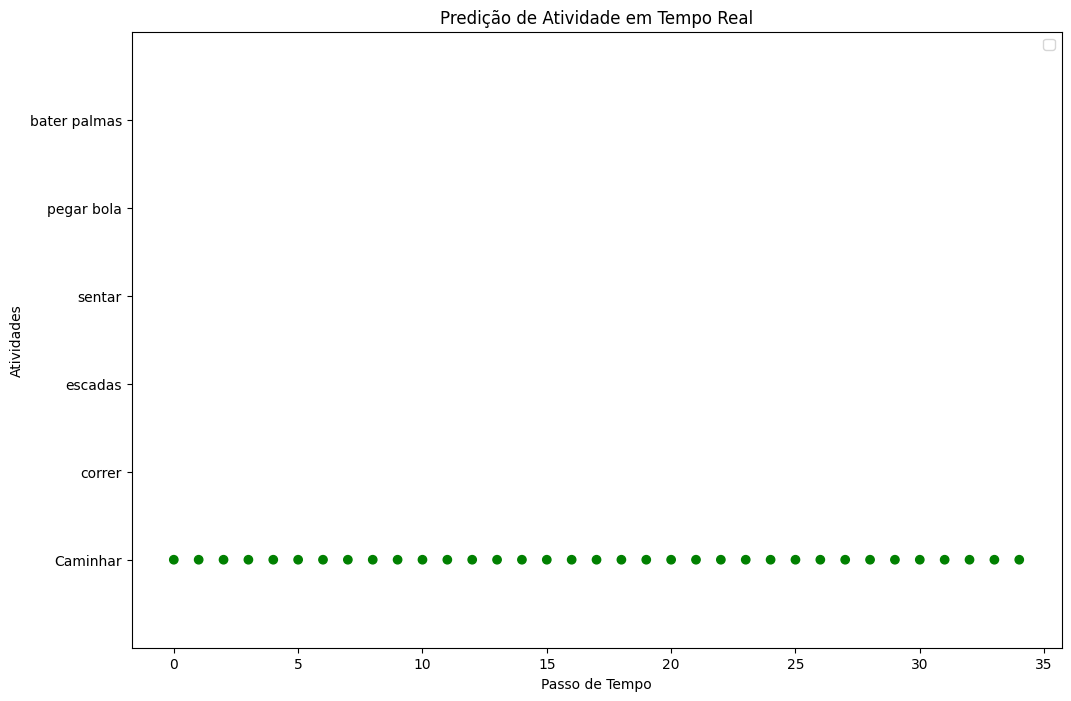

contando 35
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

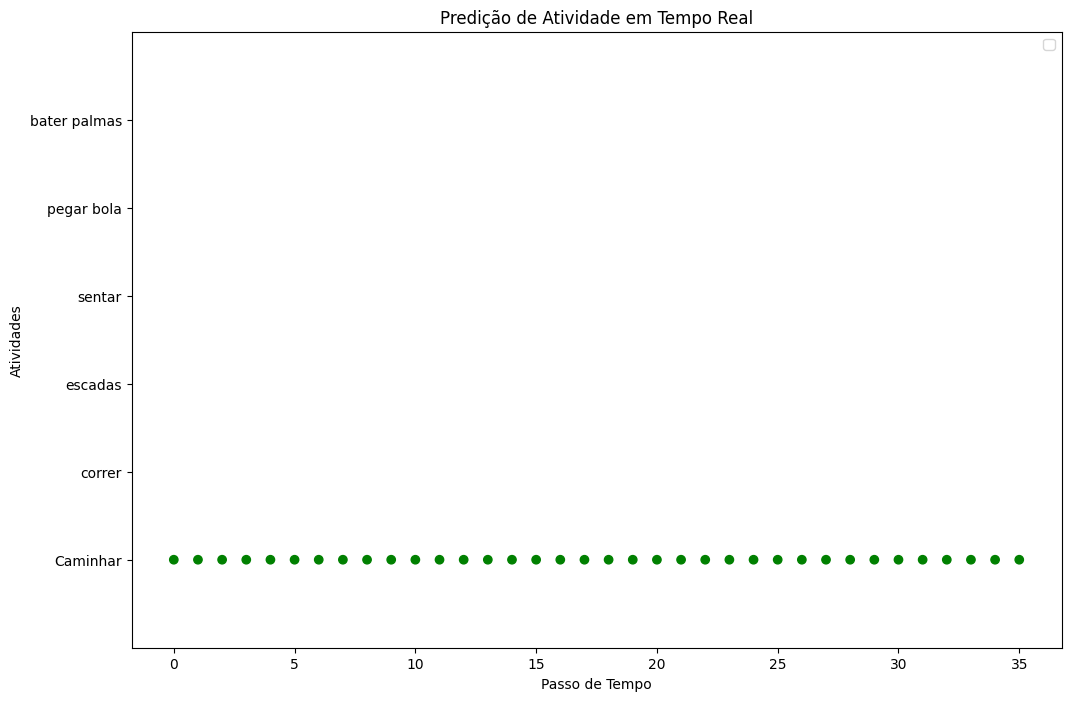

contando 36
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

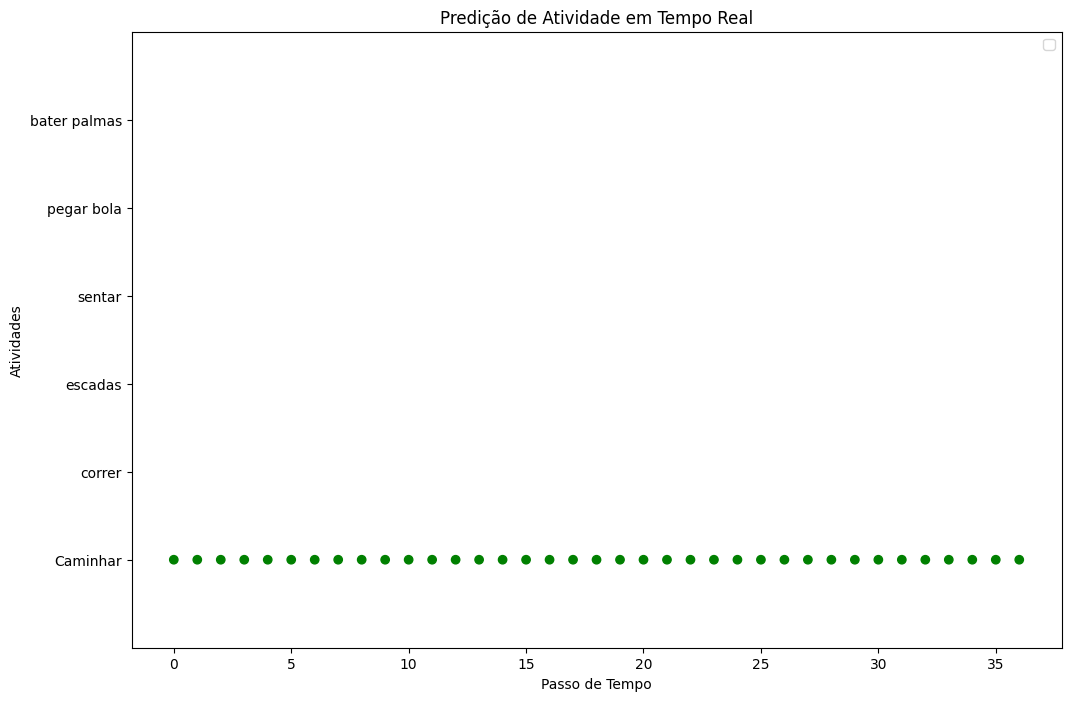

contando 37
(200, 6)
(200,)
0
1/1 [==============================] - 0s 21ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

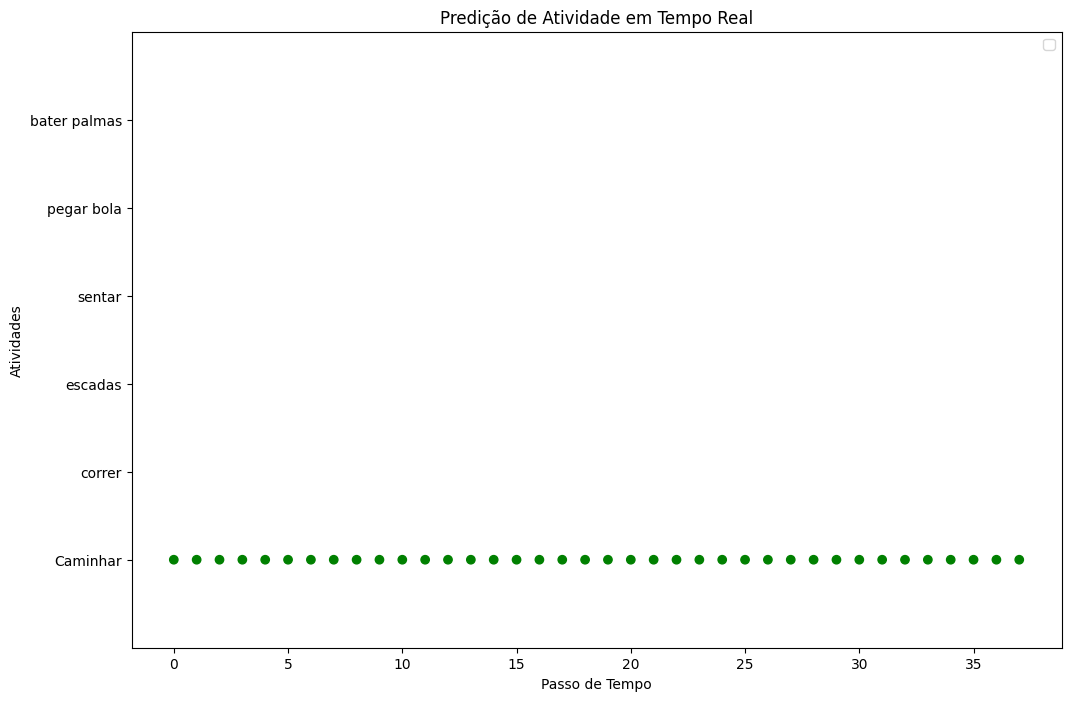

contando 38
(200, 6)
(200,)
0
1/1 [==============================] - 0s 21ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

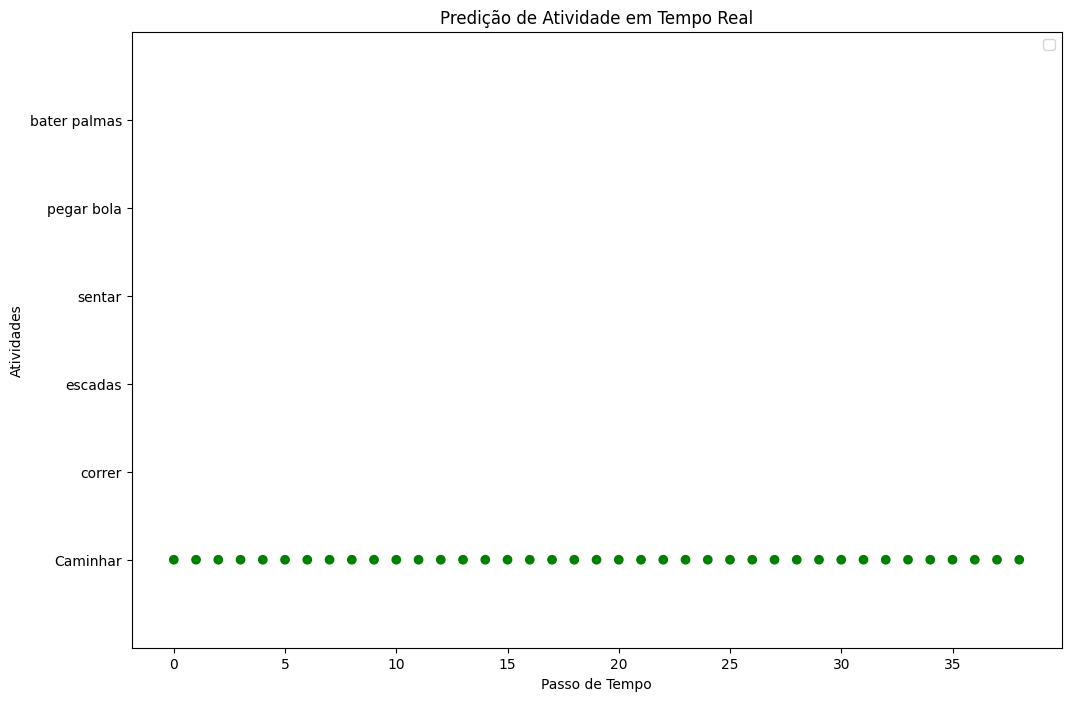

contando 39
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

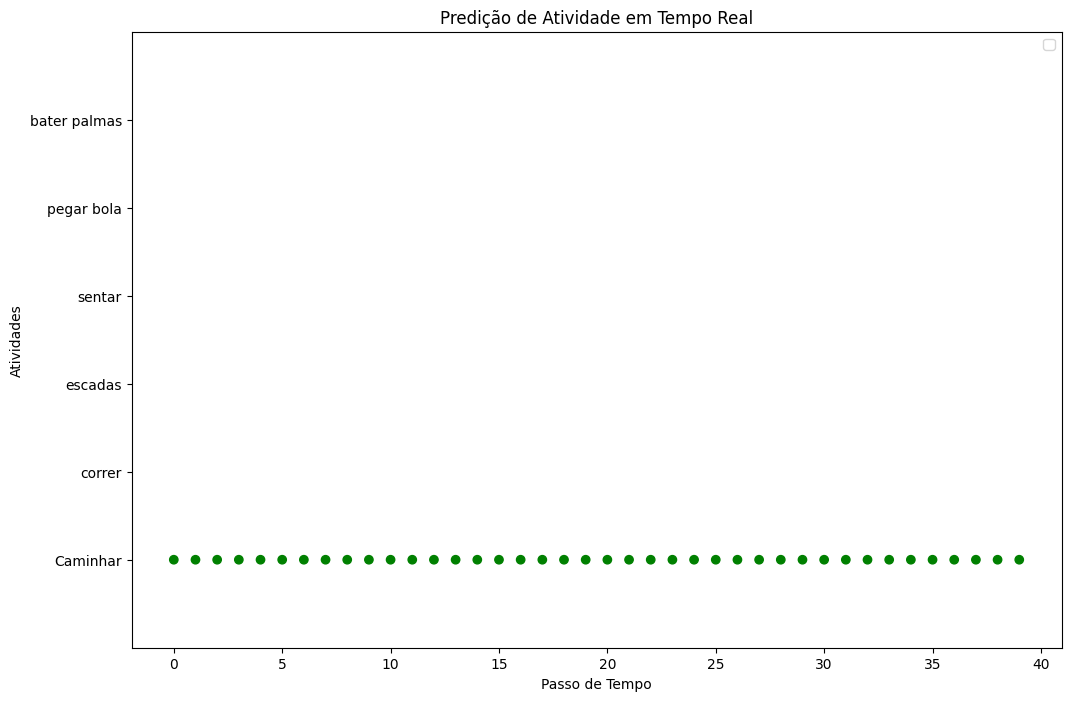

contando 40
(200, 6)
(200,)
0
1/1 [==============================] - 0s 26ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

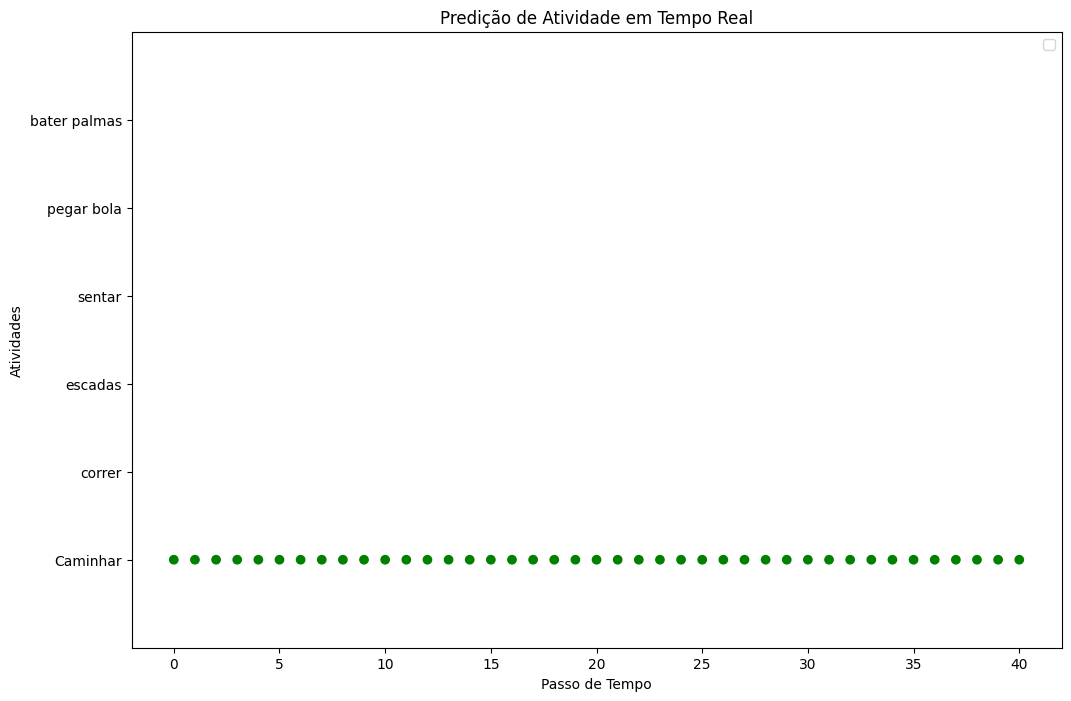

contando 41
(200, 6)
(200,)
0
1/1 [==============================] - 0s 20ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

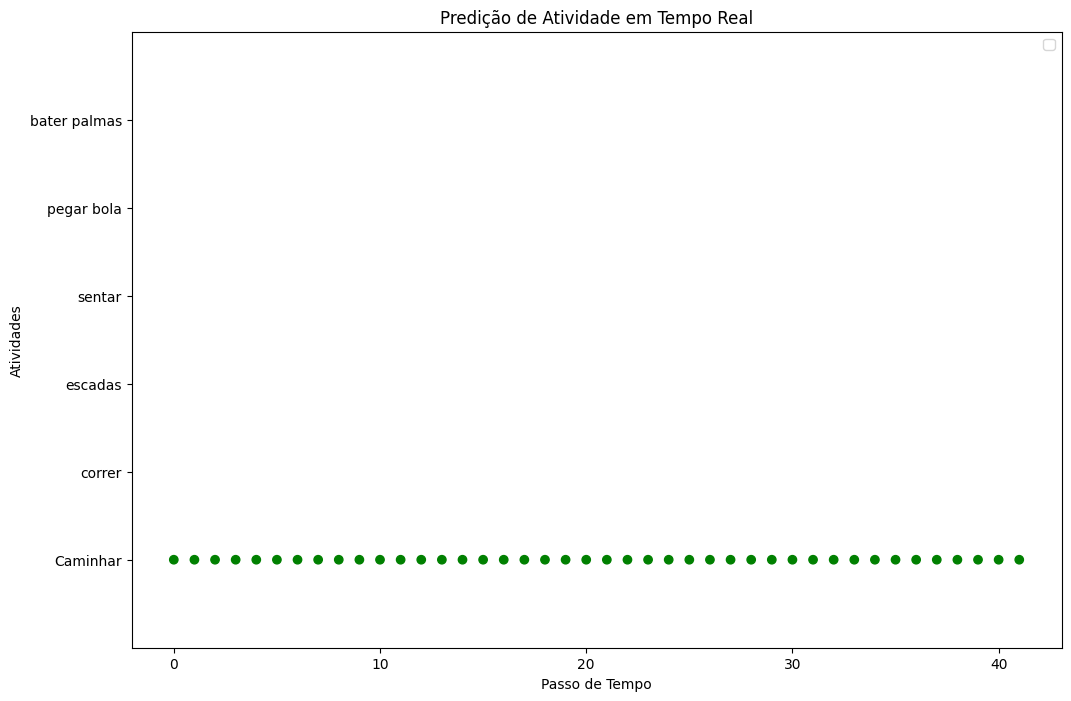

contando 42
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

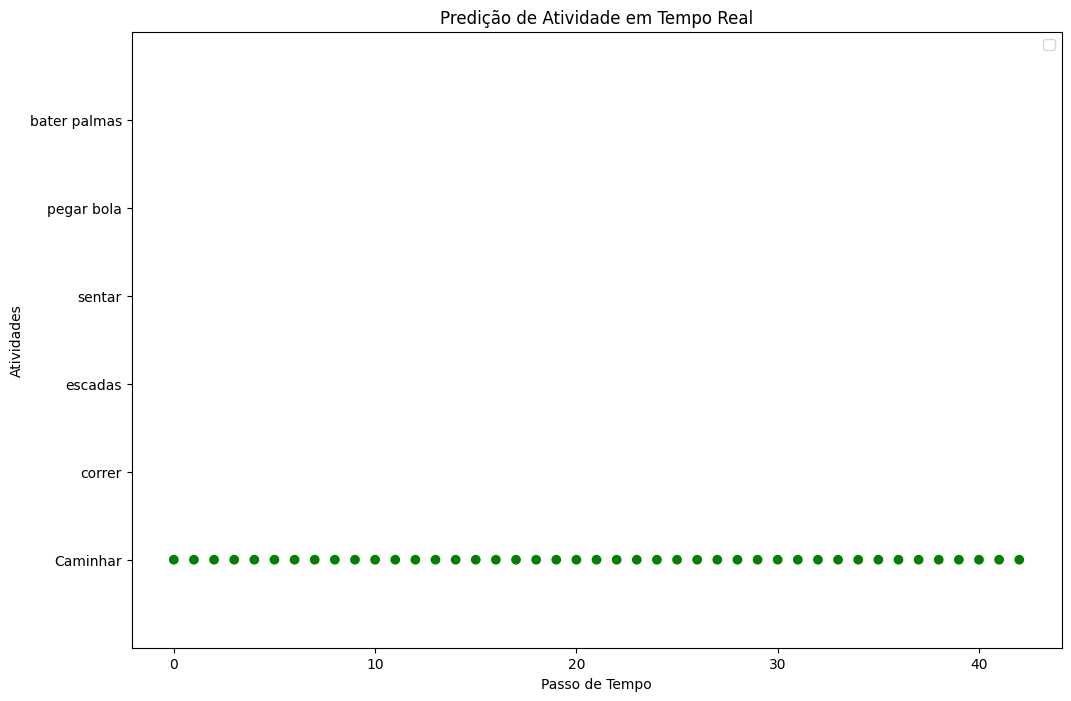

contando 43
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

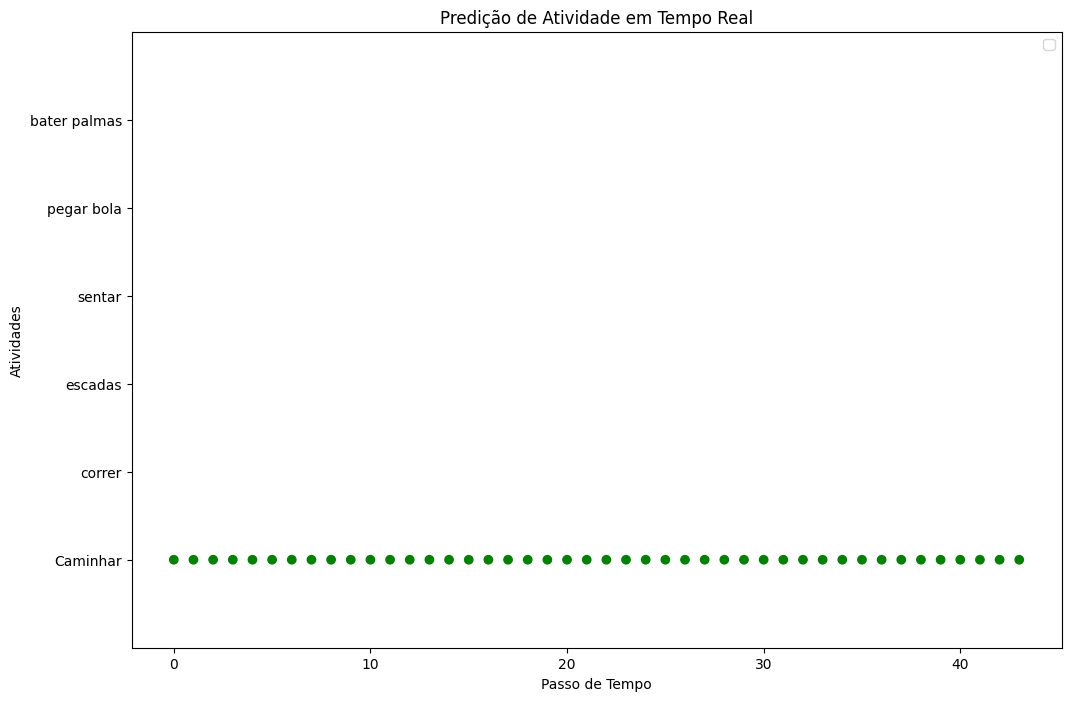

contando 44
(200, 6)
(200,)
0
1/1 [==============================] - 0s 25ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

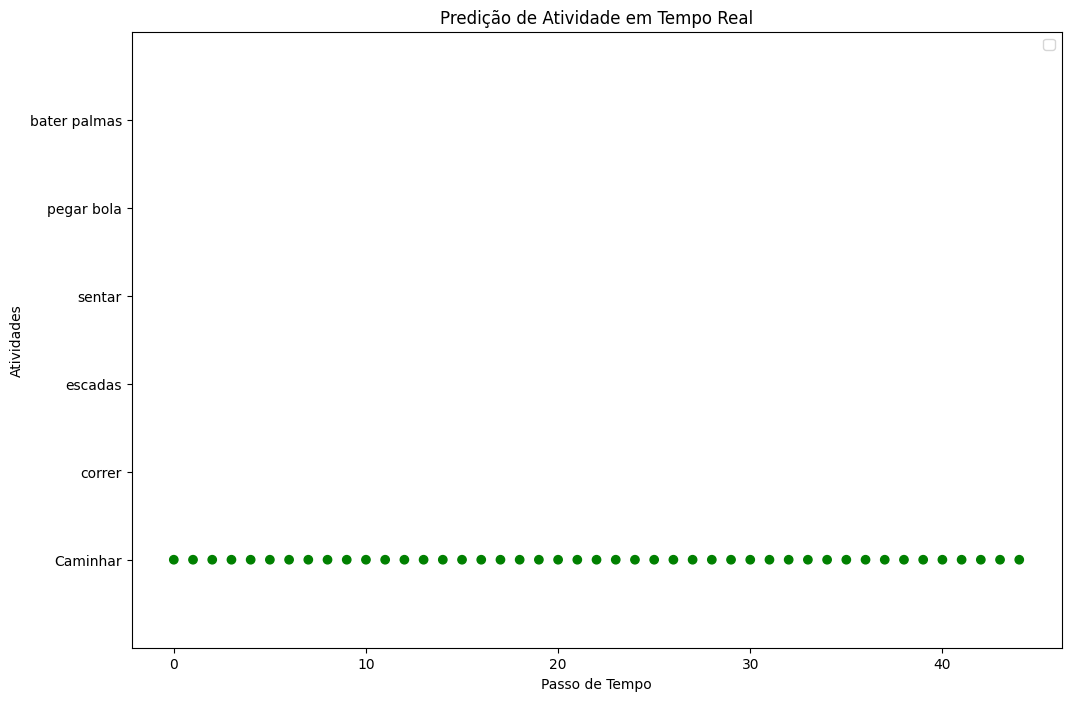

contando 45
(200, 6)
(200,)
0
1/1 [==============================] - 0s 24ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

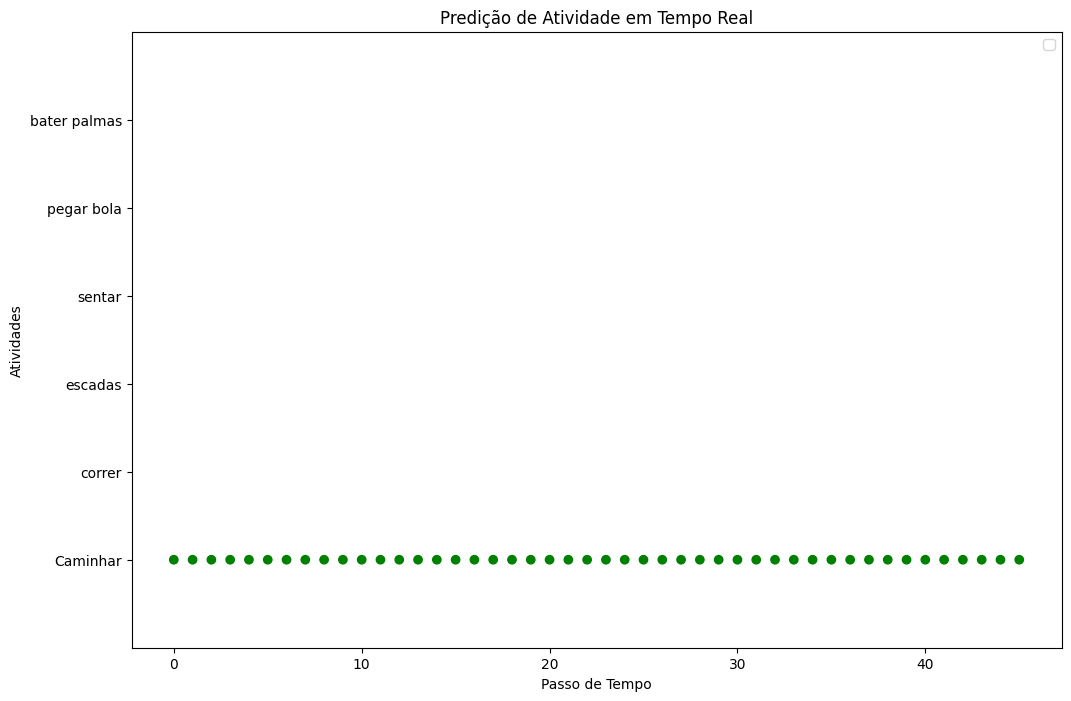

contando 46
(200, 6)
(200,)
0
1/1 [==============================] - 0s 30ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

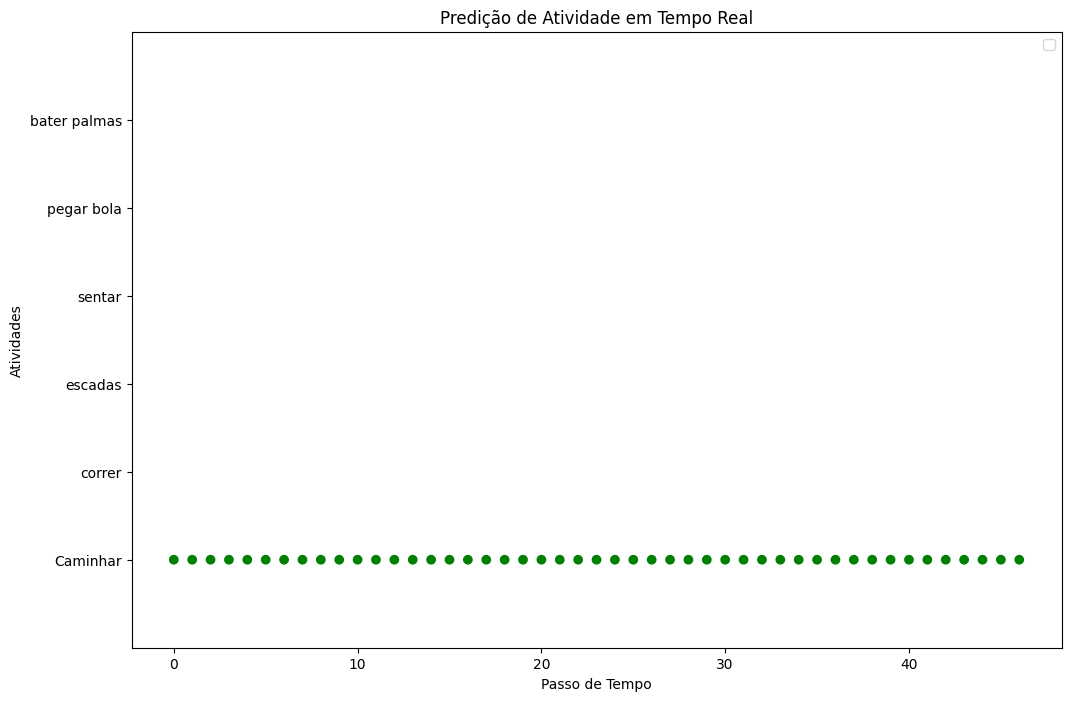

contando 47
(200, 6)
(200,)
0
1/1 [==============================] - 0s 103ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

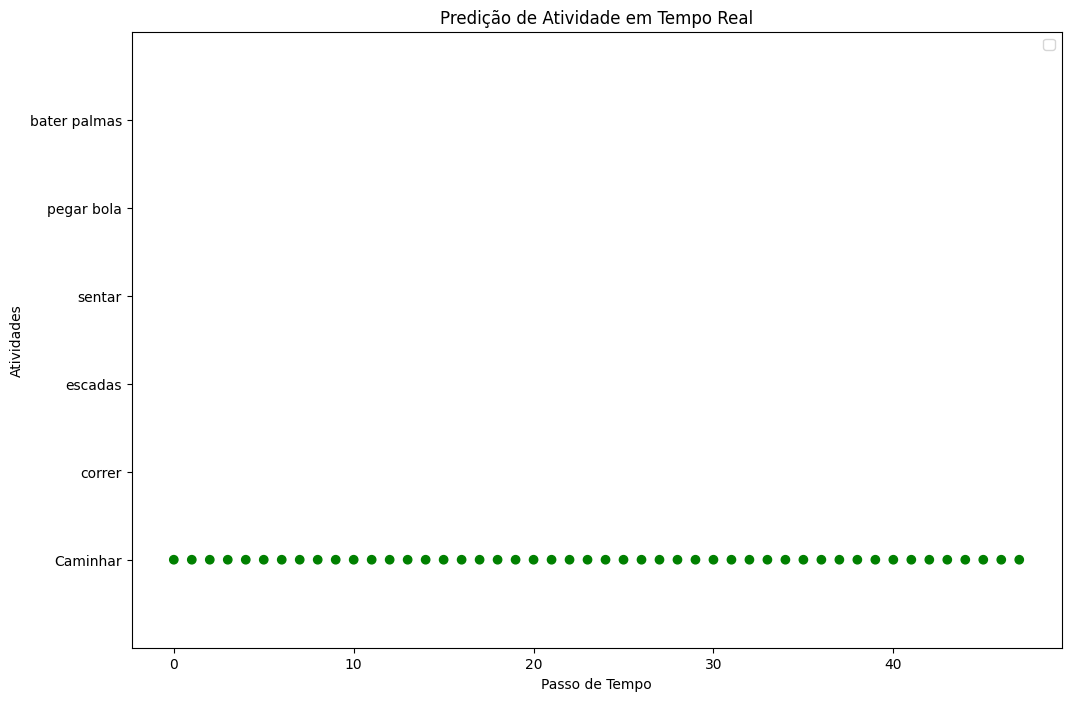

contando 48
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

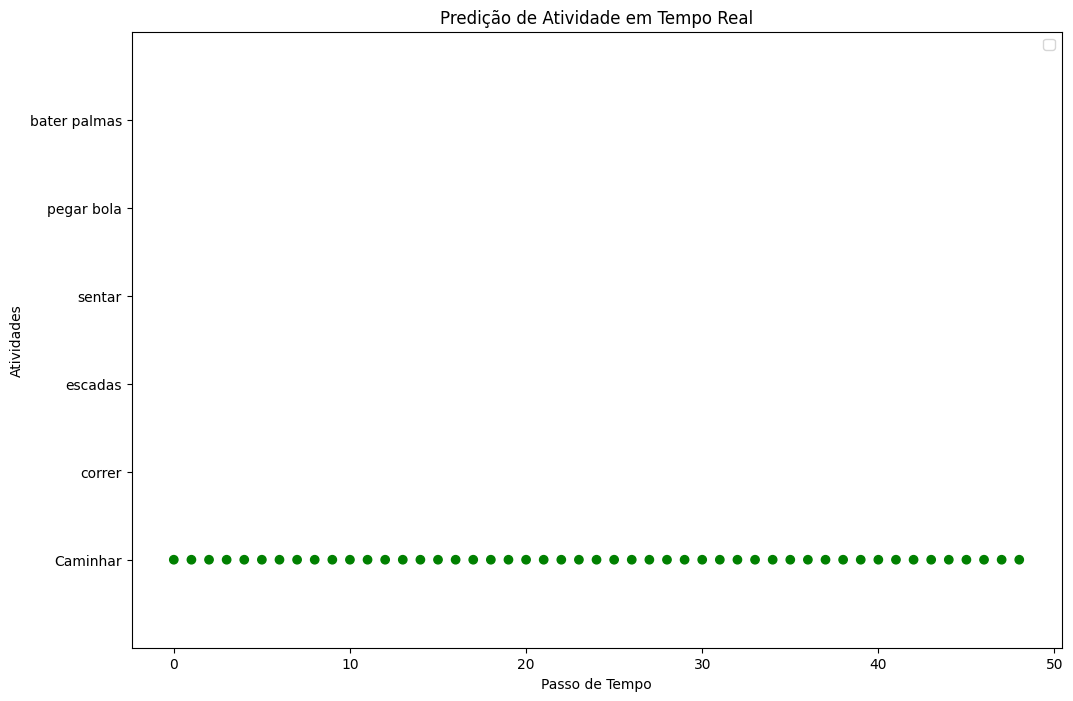

contando 49
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

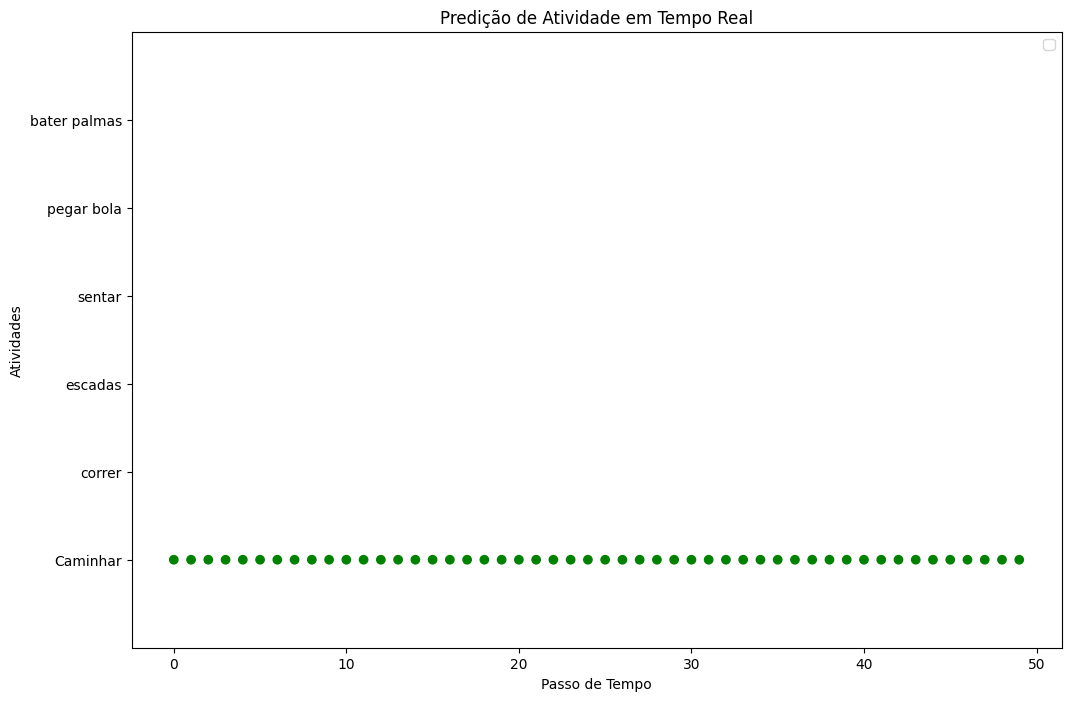

contando 50
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step
contando 51
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step
contando 52
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step
contando 53
(200, 6)
(200,)
0
1/1 [==============================] - 0s 23ms/step
contando 54
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step
contando 55
(200, 6)
(200,)
0
1/1 [==============================] - 0s 21ms/step
contando 56
(200, 6)
(200,)
0
1/1 [==============================] - 0s 21ms/step
contando 57
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step
contando 58
(200, 6)
(200,)
0
1/1 [==============================] - 0s 21ms/step
contando 59
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step
contando 60
(200, 6)
(200,)
0
1/1 [==============================] - 0s 22ms/step
contando 61
(200, 6)
(200,)
0
1/1 [==============================] - 0s 20ms/step
contando 62
(200

<Figure size 640x480 with 0 Axes>

In [62]:

X_test_data = X_test_data.loc[X_test_data['pessoa_x'] == 1613]
X_test_data_filtered = X_test_data.loc[:, X_test_data.columns != 'pessoa_x']

first_window_xdata = X_test_data_filtered.iloc[:200,:-1]  # Get the latest window of data    
first_window_label = X_test_data_filtered.iloc[:200,-1]
mixed_data = False
def prepare_data(test_data,window_size,sensor_data_dim,primeira_janela):
  global mixed_data  
  global first_window_xdata
  global first_window_label  

  if primeira_janela == True:
    # Assuming data is a continuous stream of sensor readings
    window_xdata = first_window_xdata # Get the latest window of data  
    window_label = first_window_label    
  else:
    window_xdata =pd.concat([first_window_xdata[:180], test_data.iloc[:20,:-1]], ignore_index=True)  
    window_label =pd.concat([first_window_label[:180],test_data.iloc[:20,-1]],ignore_index=True)
    if len(np.unique(window_label)) == 1:
      first_window_xdata = window_xdata  
      first_window_label = window_label
      mixed_data = False
    else:
      mixed_data = True
      first_window_xdata = test_data.iloc[:200,:-1]
      first_window_label = test_data.iloc[:200,-1]

  window_array = window_xdata.values
  window_label_array = window_label.values  
  print(window_xdata.shape)
  print(window_label.shape)
  window_label_array = window_label_array[0]
  print(window_label_array)
  return (window_array.reshape((1, window_size, sensor_data_dim)),window_label_array)  # Reshape for LSTM input

# Real-time prediction loop with plotting
ground_truth = []  # List to store true activity labels
predicted_activities = []  # List to store predicted activity labels
colors = ['green', 'red']  # Green for correct, red for incorrect

count = 0
while not X_test_data_filtered.empty and X_test_data_filtered.shape[0]>199:  
  if count == 0:
    new_xdata, true_activity_label = prepare_data(X_test_data_filtered,200,6,True)
  else:
    new_xdata, true_activity_label = prepare_data(X_test_data_filtered,200,6,False)  
  count = count + 1
  prediction = lstm_model.predict(new_xdata)
  predicted_activity = np.argmax(prediction[0])  # Get the class with highest probability
  ground_truth.append(true_activity_label)  # Store true label
  predicted_activities.append(predicted_activity)
  colors = ['red' if pred != true_val else 'green' for pred, true_val in zip(predicted_activities, ground_truth)]

  # Prepare data for scatter plot (assuming multiple data points per time step)
  x_data = range(len(predicted_activities))  # Time steps
  y_data = predicted_activities  # Predicted activities (can be modified for other dimensions)
  

  if 1 <= count <= 50:
    # Create the scatter plot with optional error bars (consider for uncertainty visualization)
    plt.figure(figsize=(12, 8))  # Adjust figure size as needed
    plt.scatter(x_data, y_data, marker='o', c = colors)  # Default green for prediction
    # plt.errorbar(x_data, y_data, yerr=error_bars, fmt='o', capsize=5, color=colors[0])  # Uncomment for error bars

    # Update plot with true label if available (consider different color/marker)
    #if true_activity_label is not None:
      #plt.scatter(count, true_activity_label, marker='s', color=colors[1], label='True Label')  # Red for true label (optional)

    plt.xlabel("Passo de Tempo")
    plt.ylabel("Atividades")  # Adjust label based on data
    plt.ylim(-1, 6)  # Adjust y-axis based on number of activity classes (or data range)
    plt.yticks([0, 1, 2, 3, 4, 5], ['Caminhar', 'correr', 'escadas', 'sentar', 'pegar bola', 'bater palmas'])
    plt.title("Predição de Atividade em Tempo Real")
    plt.legend() if true_activity_label is not None else None  # Show legend if true label is displayed
    plt.pause(0.1)  # Adjust pause time for smoother visualization

    plt.ion()
    plt.show()

    # Clear plot for next iteration or consider animation for smoother transition
    plt.clf() 
  if mixed_data == False:  
    X_test_data_filtered = X_test_data_filtered.iloc[20:]
  else:
    X_test_data_filtered = X_test_data_filtered.iloc[200:]   
  print(f"contando {count}")



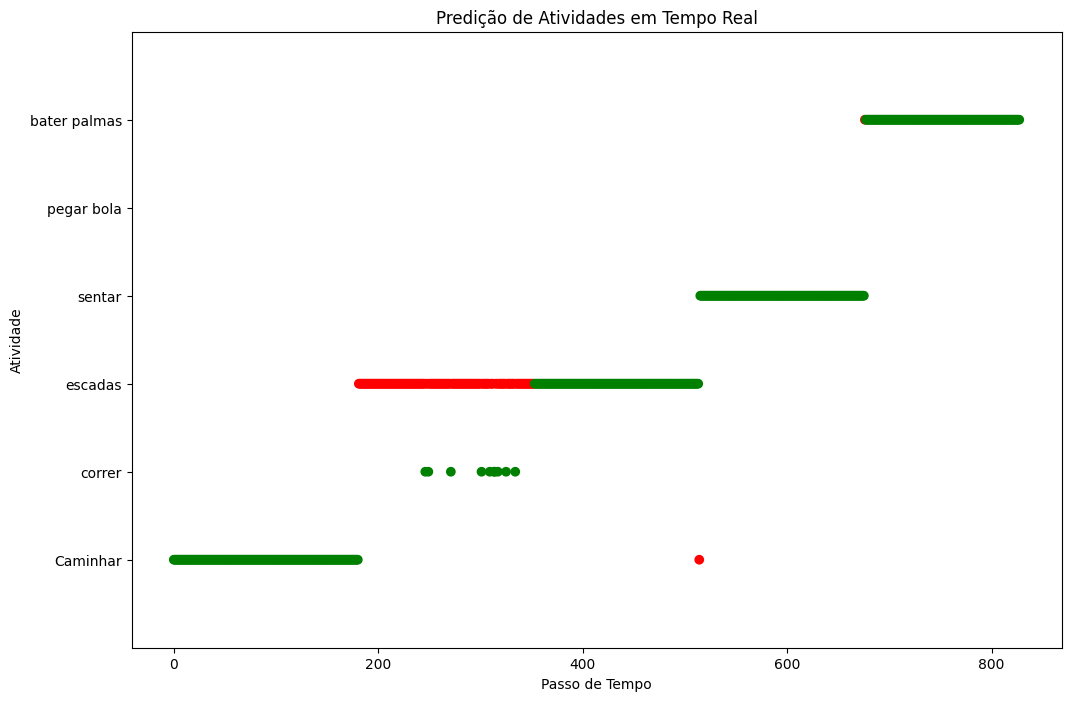

<Figure size 640x480 with 0 Axes>

In [63]:
   
colors = ['red' if pred != true_val else 'green' for pred, true_val in zip(predicted_activities, ground_truth)]

# Prepare data for scatter plot (assuming multiple data points per time step)
x_data = range(len(predicted_activities))  # Time steps
y_data = predicted_activities  # Predicted activities (can be modified for other dimensions)


# Create the scatter plot with optional error bars (consider for uncertainty visualization)
plt.figure(figsize=(12, 8))  # Adjust figure size as needed
plt.scatter(x_data, y_data, marker='o', c = colors)  # Default green for prediction
# plt.errorbar(x_data, y_data, yerr=error_bars, fmt='o', capsize=5, color=colors[0])  # Uncomment for error bars

# Update plot with true label if available (consider different color/marker)
#if true_activity_label is not None:
#plt.scatter(count, true_activity_label, marker='s', color=colors[1], label='True Label')  # Red for true label (optional)

plt.xlabel("Passo de Tempo")
plt.ylabel("Atividade")  # Adjust label based on data
plt.ylim(-1, 6)  # Adjust y-axis based on number of activity classes (or data range)
plt.title("Predição de Atividades em Tempo Real")
plt.yticks([0, 1, 2, 3, 4, 5], ['Caminhar', 'correr', 'escadas', 'sentar', 'pegar bola', 'bater palmas'])

#plt.legend() if true_activity_label is not None else None  # Show legend if true label is displayed
plt.pause(0.1)  # Adjust pause time for smoother visualization

plt.ion()
plt.show()

# Clear plot for next iteration or consider animation for smoother transition
plt.clf()

In [64]:

print(len(ground_truth))
print(len(predicted_activities))

828
828


In [65]:
print(ground_truth)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

In [66]:
print(predicted_activities)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 1, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 

In [67]:
sfasdfsa

NameError: name 'sfasdfsa' is not defined

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

predictions = np.array([0, 0, 0, 0, 0, 1])
true_values = np.array([0, 0, 0, 1, 1, 1])

colors = ['red' if pred != true_val else 'green' for pred, true_val in zip(predictions, true_values)]

plt.scatter(range(len(predictions)), predictions, c=colors)
plt.xlabel('Index')
plt.ylabel('Predictions')
plt.title('Scatter Plot of Predictions with Color Coding')
plt.show()

In [ ]:
## Python Code Example to Include New Data at the End of a DataFrame

# Import pandas library
import pandas as pd

# Create a sample DataFrame
data = {'A': [1, 2, 3],
        'B': ['apple', 'banana', 'cherry']}
df = pd.DataFrame(data)

# Create new data to include
new_data = {'A': [4],
            'B': ['date']}

# Convert new data to DataFrame
new_df = pd.DataFrame(new_data)

# Concatenate the original DataFrame with the new data
df = pd.concat([df, new_df], ignore_index=True)

# Display the updated DataFrame
print(df)

In [ ]:


import matplotlib.pyplot as plt

# Sample data
x = [1, 2, 3, 4, 5]
y = [10, 20, 30, 40, 50]

plt.plot(x, y)

# Customize y-axis tick labels
plt.yticks([0, 20, 40, 60, 80, 100], ['0', '20', '40', '60', '80', '100'])

plt.show()